# BERTopic Analysis 

In [1]:
# %pip install nltk

In [2]:
import os

try:
    base_dir = os.path.dirname(os.path.abspath(__file__))
except NameError:
    base_dir = os.getcwd()

os.chdir(base_dir)

os.getcwd()

'/opt/notebooks/psalms-text-comparison/various_research'

In [3]:
import pandas as pd
psalm_verses = pd.read_csv("../data/cleaned_psalm_verses.csv")
psalm_verses

/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


,tradition,text,psalm_num,verse_num,verse
0,Orthodox,Bible,1,1,Blessed is the man Who walks not in the counse...
1,Orthodox,Bible,1,2,But his will is in the law of the Lord And in ...
2,Orthodox,Bible,1,3,He shall be like a tree Planted by streams of ...
3,Orthodox,Bible,1,4,Not so are the ungodly not so But they are lik...
4,Orthodox,Bible,1,5,Therefore the ungodly shall not rise in the ju...
...,...,...,...,...,...
4937,Orthodox,Psalter,150,1,Praise God in His holy ones; praise Him in the...
4938,Orthodox,Psalter,150,2,Praise Him for His mighty acts; praise Him acc...
4939,Orthodox,Psalter,150,3,Praise Him with the sound of the trumpet; prai...
4940,Orthodox,Psalter,150,4,Praise Him with the timbrel and dance; praise ...


In [4]:
psalms = pd.read_csv("../data/grouped_psalm.csv")
psalms

,Unnamed: 0,tradition,text,psalm_num,verse,cleaned_verse
0,0,Orthodox,Bible,1,Blessed is the man Who walks not in the counse...,blessed man walk counsel ungodly stand way sin...
1,1,Orthodox,Bible,2,Why do the nations rage And the people meditat...,nation rage people meditate vain thing king ea...
2,2,Orthodox,Bible,3,A psalm by David when he fled from the face of...,psalm david fled face son absalom olord afflic...
3,3,Orthodox,Bible,4,For the End in psalms an ode by David You hear...,end psalm ode david heard icalled god righteou...
4,4,Orthodox,Bible,5,For the End concerning the inheritance a psalm...,end concerning inheritance psalm david give ea...
...,...,...,...,...,...,...
296,296,Orthodox,Psalter,146,The Lord doth build up Jerusalem; He shall gat...,lord doth build jerusalem ; shall gather toget...
297,297,Orthodox,Psalter,147,"Praise the Lord, O Jerusalem; praise thy God, ...","praise lord , jerusalem ; praise thy god , zio..."
298,298,Orthodox,Psalter,148,Praise ye the Lord from the heavens; praise Hi...,praise ye lord heaven ; praise highest . prais...
299,299,Orthodox,Psalter,149,"Sing unto the Lord a new song, His praise is i...","sing unto lord new song , praise congregation ..."


# BERTopic Modeling

In [5]:
import numpy as np
import scipy
import sklearn
import umap
import numba
import bertopic

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("UMAP:", umap.__version__)
print("Numba:", numba.__version__)
print("BERTopic:", bertopic.__version__)

NumPy: 1.26.4
SciPy: 1.17.1
Scikit-learn: 1.3.2
UMAP: 0.5.5
Numba: 0.58.1
BERTopic: 0.17.4


%pip install --no-cache-dir --force-reinstall \
    numpy==1.26.4 \
    scipy==1.11.4 \
    scikit-learn==1.3.2 \
    umap-learn==0.5.5 \
    numba==0.58.1 \
    bertopic==0.16.4

In [6]:
#%pip install -q sentence-transformers
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer

In [7]:
embedding_model = SentenceTransformer("all-mpnet-base-v2")
topic_model = BERTopic(embedding_model=embedding_model)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [8]:
docs = psalms["verse"].astype(str).tolist()

!pip install --upgrade bertopic umap-learn scikit-learn


In [9]:
topics, probs = topic_model.fit_transform(docs)

In [10]:
probs

array([1.        , 0.88077689, 1.        , 0.6203983 , 0.90215506,
       0.78168761, 1.        , 0.        , 0.69295403, 0.92185786,
       0.79912383, 1.        , 0.        , 0.79047838, 0.91657931,
       0.89811873, 0.62220229, 0.62432425, 1.        , 0.924952  ,
       1.        , 0.94036321, 0.        , 0.91657931, 0.73270327,
       0.80336017, 0.88796881, 0.        , 0.6170391 , 1.        ,
       0.80315863, 1.        , 0.91657931, 0.75909232, 0.54824428,
       0.92330038, 0.96037357, 0.76366908, 0.85037191, 1.        ,
       0.61634087, 0.88611562, 0.        , 0.        , 0.        ,
       0.        , 0.67125383, 0.88644088, 0.73079181, 0.99657656,
       0.72648326, 0.        , 0.77467793, 0.81736566, 0.59262447,
       0.76189037, 0.        , 0.57692746, 0.        , 0.61253967,
       1.        , 0.76831004, 1.        , 0.        , 0.61463265,
       0.54132886, 0.51588245, 0.81254089, 1.        , 0.90914492,
       0.63132015, 0.        , 0.73079181, 0.        , 0.     

In [11]:
psalms["topic"] = topics
#psalms["topic_prob"] = probs.max(axis=1)

In [12]:
psalms['topic'].value_counts()

topic
 0    73
 1    64
 2    63
-1    53
 3    36
 4    12
Name: count, dtype: int64

In [13]:
psalms

,Unnamed: 0,tradition,text,psalm_num,verse,cleaned_verse,topic
0,0,Orthodox,Bible,1,Blessed is the man Who walks not in the counse...,blessed man walk counsel ungodly stand way sin...,0
1,1,Orthodox,Bible,2,Why do the nations rage And the people meditat...,nation rage people meditate vain thing king ea...,3
2,2,Orthodox,Bible,3,A psalm by David when he fled from the face of...,psalm david fled face son absalom olord afflic...,2
3,3,Orthodox,Bible,4,For the End in psalms an ode by David You hear...,end psalm ode david heard icalled god righteou...,2
4,4,Orthodox,Bible,5,For the End concerning the inheritance a psalm...,end concerning inheritance psalm david give ea...,2
...,...,...,...,...,...,...,...
296,296,Orthodox,Psalter,146,The Lord doth build up Jerusalem; He shall gat...,lord doth build jerusalem ; shall gather toget...,1
297,297,Orthodox,Psalter,147,"Praise the Lord, O Jerusalem; praise thy God, ...","praise lord , jerusalem ; praise thy god , zio...",1
298,298,Orthodox,Psalter,148,Praise ye the Lord from the heavens; praise Hi...,praise ye lord heaven ; praise highest . prais...,1
299,299,Orthodox,Psalter,149,"Sing unto the Lord a new song, His praise is i...","sing unto lord new song , praise congregation ...",1


In [14]:
psalms.to_csv('psalms_with_bertTopic.csv') # for the 5-topics

In [15]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,53,-1_the_and_of_for,"[the, and, of, for, in, to, his, is, shall, lord]","[O give thanks unto the Lord, for He is good; ..."
1,0,73,0_me_my_and_the,"[me, my, and, the, thy, of, in, for, lord, shall]","[O God my God, look to me; why hast Thou forsa..."
2,1,64,1_the_of_and_his,"[the, of, and, his, lord, shall, in, he, all, is]","[I will give thanks unto Thee, O Lord, with my..."
3,2,63,2_my_you_the_me,"[my, you, the, me, and, of, in, your, to, will]",[For the End concerning help in the morning a ...
4,3,36,3_the_and_of_he,"[the, and, of, he, their, they, them, his, in,...","[O give thanks unto the Lord, for He is good; ..."
5,4,12,4_the_lord_from_us,"[the, lord, from, us, of, soul, who, israel, i...",[1An ode of ascents Ilifted my eyes to the mou...


In [16]:
topic_model.visualize_topics()

In [17]:
psalms['cleaned_verse']

0      blessed man walk counsel ungodly stand way sin...
1      nation rage people meditate vain thing king ea...
2      psalm david fled face son absalom olord afflic...
3      end psalm ode david heard icalled god righteou...
4      end concerning inheritance psalm david give ea...
                             ...                        
296    lord doth build jerusalem ; shall gather toget...
297    praise lord , jerusalem ; praise thy god , zio...
298    praise ye lord heaven ; praise highest . prais...
299    sing unto lord new song , praise congregation ...
300     praise god holy one ; praise firmament power ...
Name: cleaned_verse, Length: 301, dtype: str

In [18]:
docs = psalms["cleaned_verse"].astype(str).tolist()

In [19]:
topics, probs = topic_model.fit_transform(docs)

In [20]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,90,-1_lord_shall_god_mercy,"[lord, shall, god, mercy, give, hand, earth, u...",[alleluia give thanks lord good mercy endures ...
1,0,77,0_thy_me_thou_lord,"[thy, me, thou, lord, thee, unto, shall, hast,...","[blessed blameless way , walk law lord . bless..."
2,1,52,1_shall_lord_god_man,"[shall, lord, god, man, like, let, heart, soul...",[onefor end corrupt david pillar inscription s...
3,2,33,2_lord_god_shall_unto,"[lord, god, shall, unto, thou, thy, zion, moun...","[israel went egypt , house jacob among barbaro..."
4,3,27,3_lord_praise_thy_shall,"[lord, praise, thy, shall, ever, unto, thou, g...",[heart hath uttered good word ; speak work unt...
5,4,12,4_lord_earth_shall_people,"[lord, earth, shall, people, king, holy, glory...",[psalm david sing new song lord wondrous thing...
6,5,10,5_god_commandment_lord_shall,"[god, commandment, lord, shall, ordinance, law...",[onefor end child lord david thing spoke lord ...


In [21]:
import pandas as pd

pd.Series(topics).unique()
#pd.Series(topics).count()

array([ 0,  4,  1, -1,  5,  2,  3])

In [22]:
topic_words = topic_model.get_topics()

# topic_words

In [23]:
topic_sets = {}

for topic_id, words_scores in topic_words.items():
    if topic_id == -1:
        continue

    topic_sets[topic_id] = {
        word for word, score in words_scores[:10]
    }

In [24]:
from itertools import combinations

for t1, t2 in combinations(topic_sets.keys(), 2):
    overlap = topic_sets[t1] & topic_sets[t2]

    print(f"Topic {t1} vs Topic {t2}")
    print(f"Shared words: {overlap}")
    print(f"Count: {len(overlap)}\n")

Topic 0 vs Topic 1
Shared words: {'lord', 'god', 'shall'}
Count: 3

Topic 0 vs Topic 2
Shared words: {'thou', 'thy', 'god', 'shall', 'lord', 'unto'}
Count: 6

Topic 0 vs Topic 3
Shared words: {'thou', 'thy', 'god', 'shall', 'lord', 'unto'}
Count: 6

Topic 0 vs Topic 4
Shared words: {'lord', 'god', 'shall'}
Count: 3

Topic 0 vs Topic 5
Shared words: {'lord', 'god', 'shall'}
Count: 3

Topic 1 vs Topic 2
Shared words: {'lord', 'god', 'shall'}
Count: 3

Topic 1 vs Topic 3
Shared words: {'lord', 'god', 'shall'}
Count: 3

Topic 1 vs Topic 4
Shared words: {'lord', 'let', 'god', 'shall'}
Count: 4

Topic 1 vs Topic 5
Shared words: {'lord', 'let', 'god', 'shall'}
Count: 4

Topic 2 vs Topic 3
Shared words: {'thou', 'thy', 'earth', 'god', 'shall', 'lord', 'unto'}
Count: 7

Topic 2 vs Topic 4
Shared words: {'earth', 'lord', 'god', 'shall'}
Count: 4

Topic 2 vs Topic 5
Shared words: {'lord', 'god', 'shall'}
Count: 3

Topic 3 vs Topic 4
Shared words: {'earth', 'lord', 'god', 'shall'}
Count: 4

Topic 

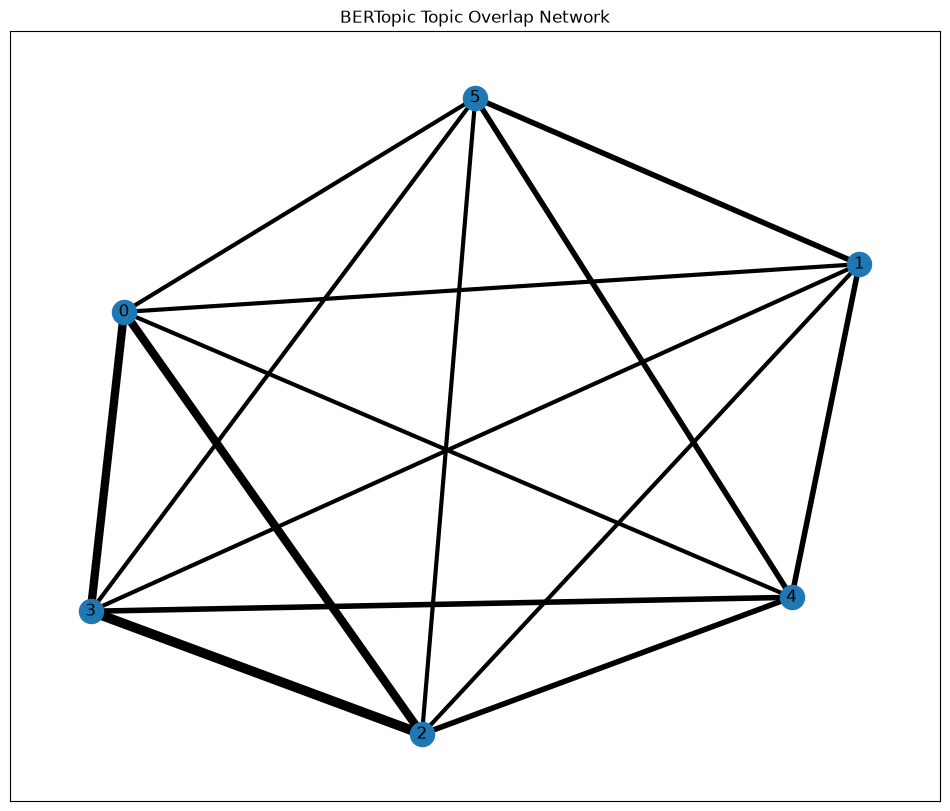

In [25]:
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations

G = nx.Graph()

for topic in topic_sets:
    G.add_node(topic)

for t1, t2 in combinations(topic_sets.keys(), 2):
    overlap = len(topic_sets[t1] & topic_sets[t2])

    if overlap > 0:
        G.add_edge(t1, t2, weight=overlap)

plt.figure(figsize=(12, 10))

pos = nx.spring_layout(G, seed=42)

edge_widths = [
    G[u][v]["weight"]
    for u, v in G.edges()
]

nx.draw_networkx_nodes(G, pos)
nx.draw_networkx_labels(G, pos)
nx.draw_networkx_edges(
    G,
    pos,
    width=edge_widths
)

plt.title("BERTopic Topic Overlap Network")
plt.show()

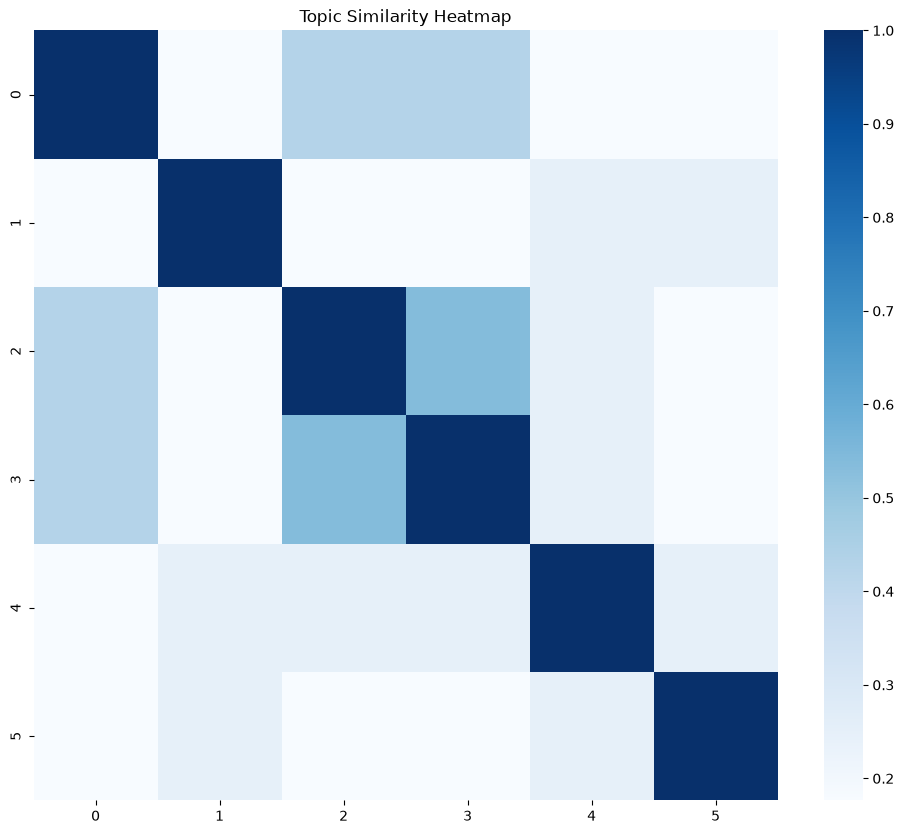

In [26]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

topic_ids = list(topic_sets.keys())

matrix = pd.DataFrame(
    index=topic_ids,
    columns=topic_ids
)

for t1 in topic_ids:
    for t2 in topic_ids:
        intersection = len(topic_sets[t1] & topic_sets[t2])
        union = len(topic_sets[t1] | topic_sets[t2])

        matrix.loc[t1, t2] = intersection / union

matrix = matrix.astype(float)

plt.figure(figsize=(12,10))
sns.heatmap(matrix, cmap="Blues")
plt.title("Topic Similarity Heatmap")
plt.show()

In [27]:
from sklearn.cluster import KMeans

cluster_model = KMeans(
    n_clusters=5,
    random_state=42
)

topic_model = BERTopic(
    hdbscan_model=cluster_model
)

In [28]:
docs = psalms["cleaned_verse"].astype(str).tolist()

In [29]:
topics, probs = topic_model.fit_transform(docs)

topic_model.get_topic_info()

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,Topic,Count,Name,Representation,Representative_Docs
0,0,110,0_shall_lord_god_let,"[shall, lord, god, let, like, hand, earth, man...",[end concerning hidden thing son psalm david i...
1,1,70,1_thy_me_thou_lord,"[thy, me, thou, lord, shall, thee, unto, god, ...","[blessed blameless way , walk law lord . bless..."
2,2,50,2_lord_shall_unto_god,"[lord, shall, unto, god, ye, earth, hath, isra...","[sing unto lord new song ; sing unto lord , ea..."
3,3,45,3_thy_thou_shall_ever,"[thy, thou, shall, ever, lord, god, hast, unto...","[give thee thanks , lord , whole heart : angel..."
4,4,26,4_lord_forever_praise_shall,"[lord, forever, praise, shall, endures, comman...",[concerning understanding asaph give heed peop...


In [30]:
topic_words = topic_model.get_topics()

# topic_words

In [31]:
topic_sets = {}

for topic_id, words_scores in topic_words.items():
    if topic_id == -1:
        continue

    topic_sets[topic_id] = {
        word for word, score in words_scores[:10]
    }

In [32]:
from itertools import combinations

for t1, t2 in combinations(topic_sets.keys(), 2):
    overlap = topic_sets[t1] & topic_sets[t2]

    print(f"Topic {t1} vs Topic {t2}")
    print(f"Shared words: {overlap}")
    print(f"Count: {len(overlap)}\n")

Topic 0 vs Topic 1
Shared words: {'lord', 'god', 'shall'}
Count: 3

Topic 0 vs Topic 2
Shared words: {'earth', 'lord', 'god', 'shall'}
Count: 4

Topic 0 vs Topic 3
Shared words: {'lord', 'god', 'shall'}
Count: 3

Topic 0 vs Topic 4
Shared words: {'lord', 'shall'}
Count: 2

Topic 1 vs Topic 2
Shared words: {'god', 'shall', 'lord', 'unto', 'hath'}
Count: 5

Topic 1 vs Topic 3
Shared words: {'thou', 'thy', 'hast', 'god', 'shall', 'unto', 'lord', 'thee', 'hath'}
Count: 9

Topic 1 vs Topic 4
Shared words: {'lord', 'shall'}
Count: 2

Topic 2 vs Topic 3
Shared words: {'god', 'shall', 'lord', 'unto', 'hath'}
Count: 5

Topic 2 vs Topic 4
Shared words: {'lord', 'shall'}
Count: 2

Topic 3 vs Topic 4
Shared words: {'lord', 'shall'}
Count: 2



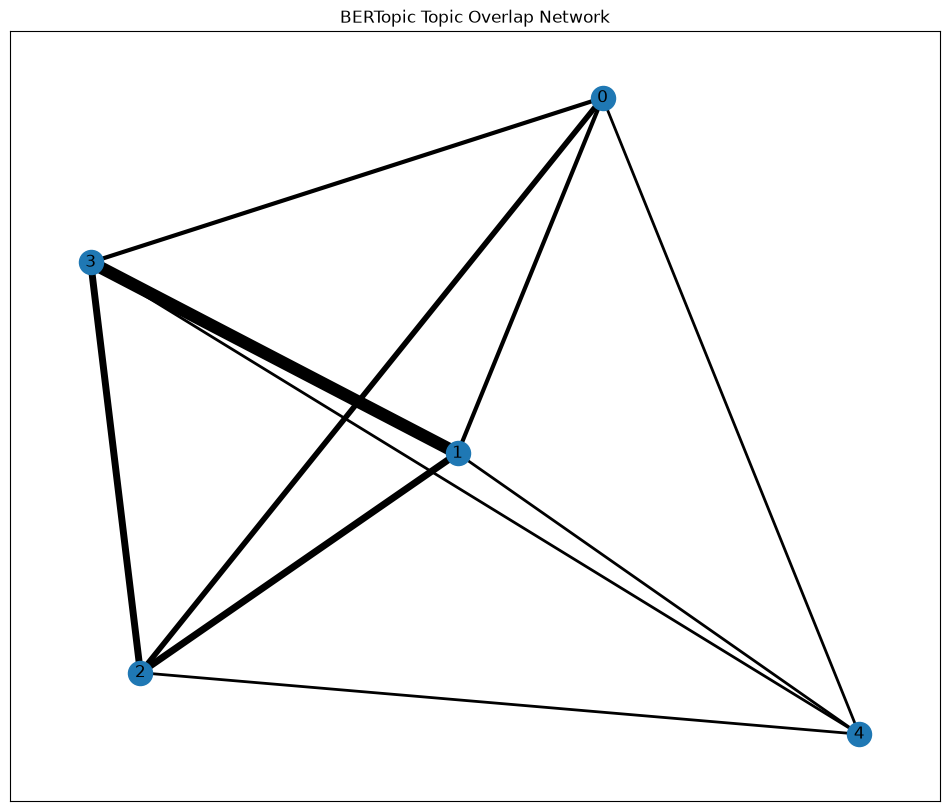

In [33]:
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations

G = nx.Graph()

for topic in topic_sets:
    G.add_node(topic)

for t1, t2 in combinations(topic_sets.keys(), 2):
    overlap = len(topic_sets[t1] & topic_sets[t2])

    if overlap > 0:
        G.add_edge(t1, t2, weight=overlap)

plt.figure(figsize=(12, 10))

pos = nx.spring_layout(G, seed=42)

edge_widths = [
    G[u][v]["weight"]
    for u, v in G.edges()
]

nx.draw_networkx_nodes(G, pos)
nx.draw_networkx_labels(G, pos)
nx.draw_networkx_edges(
    G,
    pos,
    width=edge_widths
)

plt.title("BERTopic Topic Overlap Network")
plt.show()

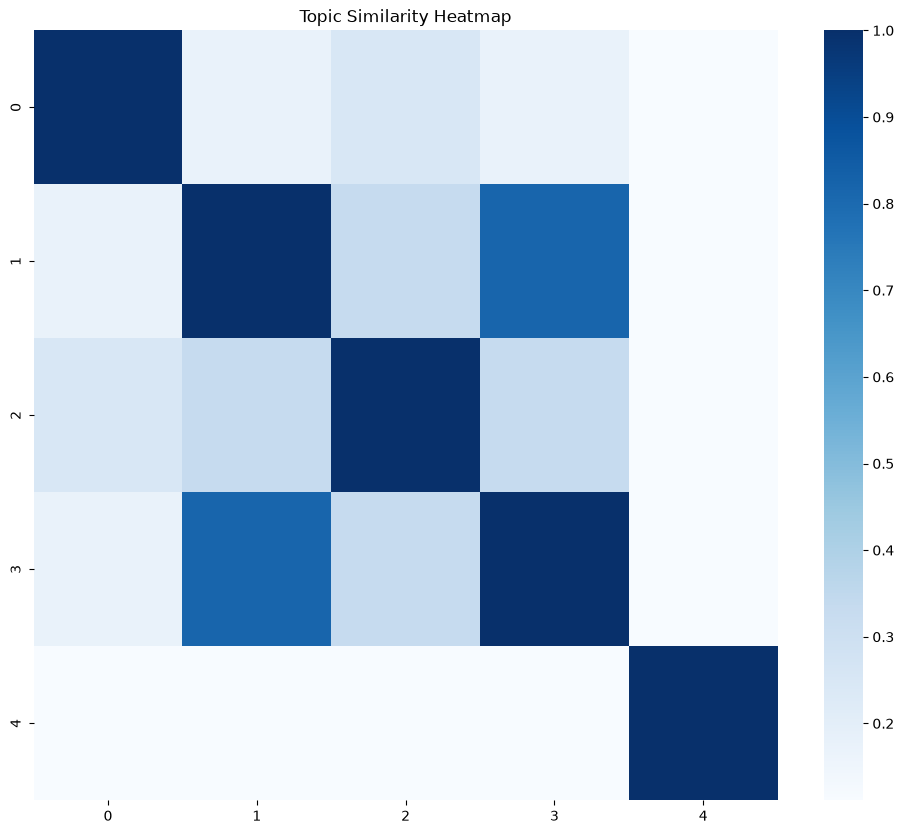

In [34]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

topic_ids = list(topic_sets.keys())

matrix = pd.DataFrame(
    index=topic_ids,
    columns=topic_ids
)

for t1 in topic_ids:
    for t2 in topic_ids:
        intersection = len(topic_sets[t1] & topic_sets[t2])
        union = len(topic_sets[t1] | topic_sets[t2])

        matrix.loc[t1, t2] = intersection / union

matrix = matrix.astype(float)

plt.figure(figsize=(12,10))
sns.heatmap(matrix, cmap="Blues")
plt.title("Topic Similarity Heatmap")
plt.show()

## Topic modeling comparison

Looking at possible topics that are being models based on wheather it is a Psalms from the bible or the psalter

In [35]:
from sklearn.cluster import KMeans

cluster_model = KMeans(
    n_clusters=5,
    random_state=42
)

topic_model = BERTopic(
    hdbscan_model=cluster_model
)

In [36]:
bible = psalms[psalms['text'] == "Bible"]
bible

,Unnamed: 0,tradition,text,psalm_num,verse,cleaned_verse,topic
0,0,Orthodox,Bible,1,Blessed is the man Who walks not in the counse...,blessed man walk counsel ungodly stand way sin...,0
1,1,Orthodox,Bible,2,Why do the nations rage And the people meditat...,nation rage people meditate vain thing king ea...,3
2,2,Orthodox,Bible,3,A psalm by David when he fled from the face of...,psalm david fled face son absalom olord afflic...,2
3,3,Orthodox,Bible,4,For the End in psalms an ode by David You hear...,end psalm ode david heard icalled god righteou...,2
4,4,Orthodox,Bible,5,For the End concerning the inheritance a psalm...,end concerning inheritance psalm david give ea...,2
...,...,...,...,...,...,...,...
146,146,Orthodox,Bible,147,Alleluia of Aggeus and Zacharias Praise the Lo...,alleluia aggeus zacharias praise lord jerusale...,-1
147,147,Orthodox,Bible,148,Alleluia of Aggeus and Zacharias Praise the Lo...,alleluia aggeus zacharias praise lord heaven p...,1
148,148,Orthodox,Bible,149,1Alleluia Sing to the Lord a new song His prai...,onealleluia sing lord new song praise assembly...,1
149,149,Orthodox,Bible,150,1Alleluia Praise God in His saints Praise Him ...,onealleluia praise god saint praise firmament ...,1


In [37]:
bible_topics, bible_probs = topic_model.fit_transform(bible['cleaned_verse'])

topic_model.get_topic_info()

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,Topic,Count,Name,Representation,Representative_Docs
0,0,50,0_shall_lord_god_let,"[shall, lord, god, let, like, hand, soul, hear...",[onefor end child lord david thing spoke lord ...
1,1,34,1_god_lord_shall_earth,"[god, lord, shall, earth, people, let, psalm, ...",[end ode psalm resurrection shout god earth si...
2,2,32,2_lord_god_shall_end,"[lord, god, shall, end, man, david, heart, may...",[end psalm david deliver lord evil man rescue ...
3,3,22,3_lord_forever_shall_commandment,"[lord, forever, shall, commandment, praise, me...",[concerning understanding asaph give heed peop...
4,4,13,4_lord_onean_ascent_ode,"[lord, onean, ascent, ode, like, shall, israel...",[onean ode ascent blessed fear lord walk way s...


In [38]:
def get_topic_words(topic_model):
    pd.set_option('display.max_colwidth', None)

    return pd.DataFrame([
        {
            'Topic': topic_id,
            'Words': ', '.join(word for word, score in words)
        }
        for topic_id, words in topic_model.get_topics().items()
    ])

In [39]:
bible5_topics = topic_model

In [40]:
bible5_topic_words = get_topic_words(bible5_topics)

In [41]:
bible_topic_sets = {}

for topic_id, words_scores in topic_words.items():
    if topic_id == -1:
        continue

    bible_topic_sets[topic_id] = {
        word for word, score in words_scores[:10]
    }

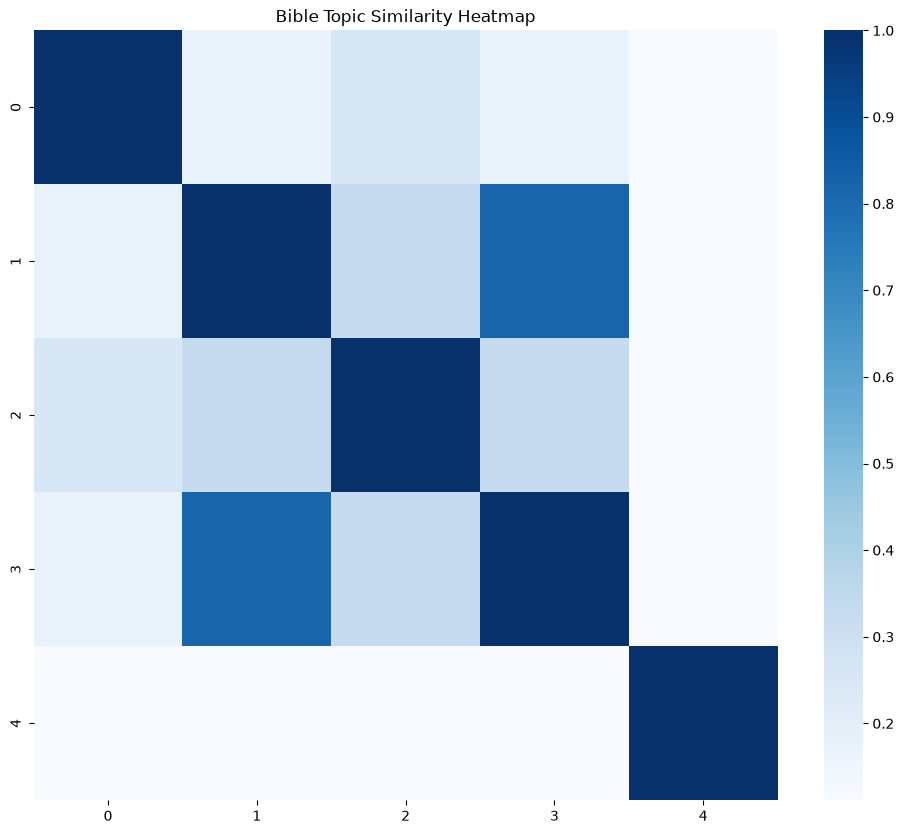

In [42]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

topic_ids = list(bible_topic_sets.keys())

matrix = pd.DataFrame(
    index=topic_ids,
    columns=topic_ids
)

for t1 in topic_ids:
    for t2 in topic_ids:
        intersection = len(topic_sets[t1] & topic_sets[t2])
        union = len(topic_sets[t1] | topic_sets[t2])

        matrix.loc[t1, t2] = intersection / union

matrix = matrix.astype(float)

plt.figure(figsize=(12,10))
sns.heatmap(matrix, cmap="Blues")
plt.title("Bible Topic Similarity Heatmap")
plt.show()

In [43]:
psalter = psalms[psalms['text'] == "Psalter"]
psalter

,Unnamed: 0,tradition,text,psalm_num,verse,cleaned_verse,topic
151,151,Orthodox,Psalter,1,"Blessed is the man that hath not walked in the counsel of the ungodly, nor stood in the way of sinners, nor sat in the seat of the pestilent. But his will is in the law of the Lord, and in His law shall he meditate day and night. And he shall be like the tree planted by the streams of waters, that shall bring forth his fruit in his season; his leaf also shall not fall, and whatsoever he doeth shall prosper. The ungodly are not so, not so: but are like the chaff which the wind driveth away from the face of the earth. Therefore the ungodly shall not rise up in the judgment, nor sinners in the congregation of the righteous. For the Lord knoweth the way of the righteous; but the way of the ungodly shall perish.","blessed man hath walked counsel ungodly , stood way sinner , sat seat pestilent . law lord , law shall meditate day night . shall like tree planted stream water , shall bring forth fruit season ; leaf also shall fall , whatsoever doeth shall prosper . ungodly so , so : like chaff wind driveth away face earth . therefore ungodly shall rise judgment , sinner congregation righteous . lord knoweth way righteous ; way ungodly shall perish .",0
152,152,Orthodox,Psalter,2,"Why did the heathen rage, and the peoples imagine vain things? The kings of the earth stood up, and the rulers were gathered together, against the Lord and against His Christ, saying, Let us break their bands asunder, and cast away their yoke from us. He that dwelleth in the heavens shall laugh them to scorn, and the Lord shall have them in derision. Then shall He speak to them in His wrath, and vex them in His sore displeasure. But I was established King by Him upon His holy mount of Zion, declaring the decree of the Lord. The Lord hath said unto me, Thou art My Son; this day have I begotten Thee. Ask of Me, and I shall give Thee the heathen for Thine inheritance, and the uttermost parts of the earth for Thy possession. Thou shalt shepherd them with a rod of iron; Thou shalt dash them in pieces like a potter's vessels. Be wise now therefore, O ye kings; be instructed, all ye judges of the earth. Serve the Lord with fear, and rejoice in Him with trembling. Embrace instruction, lest the Lord be angry, and ye perish from the righteous way, when His wrath is kindled suddenly. Blessed are all they that put their trust in Him.","heathen rage , people imagine vain thing ? king earth stood up , ruler gathered together , lord christ , saying , let u break band asunder , cast away yoke u . dwelleth heaven shall laugh scorn , lord shall derision . shall speak wrath , vex sore displeasure . established king upon holy mount zion , declaring decree lord . lord hath said unto me , thou art son ; day begotten thee . ask me , shall give thee heathen thine inheritance , uttermost part earth thy possession . thou shalt shepherd rod iron ; thou shalt dash piece like potter 's vessel . wise therefore , ye king ; instructed , ye judge earth . serve lord fear , rejoice trembling . embrace instruction , lest lord angry , ye perish righteous way , wrath kindled suddenly . blessed put trust him .",3
153,153,Orthodox,Psalter,3,"Lord, why are they increased that trouble me? many are they that rise up against me. Many there be which say to my soul, There is no salvation for him in his God. But Thou, O Lord, art my helper, my glory, and the lifter up of mine head. I cried unto the Lord with my voice, and He heard me out of His holy mount. I laid me down and slept; I arose, for the Lord will help me. I will not be afraid of ten thousands of people, that have set themselves against me round about. Arise, O Lord; save me, O my God: for Thou hast smitten all them that are mine enemies without a cause; Thou hast broken the teeth of sinners. Salvation is of the Lord, and Thy blessing is upon Thy people.","lord , increased trouble me ? many rise me . many say soul , salvation god . thou , lord , art helper

In [44]:
psalter_topics, psalter_probs = topic_model.fit_transform(psalter['cleaned_verse'])

topic_model.get_topic_info()

Topic  Count                    Name  \
0      0     45     0_lord_thy_thou_god   
1      1     36      1_me_lord_thou_thy   
2      2     27    2_shall_god_lord_thy   
3      3     26   3_thy_shall_lord_thou   
4      4     16  4_lord_praise_ye_earth   

                                                      Representation  \
0       [lord, thy, thou, god, shall, unto, ever, hath, thee, mercy]   
1           [me, lord, thou, thy, unto, shall, thee, god, let, hast]   
2     [shall, god, lord, thy, thou, unto, earth, thee, upon, israel]   
3  [thy, shall, lord, thou, me, word, heart, commandment, thee, law]   
4      [lord, praise, ye, earth, shall, glory, unto, god, sing, him]   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               

In [45]:
psalter5_topics = get_topic_words(topic_model)

In [46]:
all_topics = topic_model.get_topics()

all_topics_words = {
    topic_id: [word for word, score in words]
    for topic_id, words in all_topics.items()
}

print(all_topics_words)

{0: ['lord', 'thy', 'thou', 'god', 'shall', 'unto', 'ever', 'hath', 'thee', 'mercy'], 1: ['me', 'lord', 'thou', 'thy', 'unto', 'shall', 'thee', 'god', 'let', 'hast'], 2: ['shall', 'god', 'lord', 'thy', 'thou', 'unto', 'earth', 'thee', 'upon', 'israel'], 3: ['thy', 'shall', 'lord', 'thou', 'me', 'word', 'heart', 'commandment', 'thee', 'law'], 4: ['lord', 'praise', 'ye', 'earth', 'shall', 'glory', 'unto', 'god', 'sing', 'him']}


In [47]:
topic_model.get_topics()

{0: [('lord', 0.07247953663516377),
  ('thy', 0.06134621063571652),
  ('thou', 0.05937542421443199),
  ('god', 0.05693543022780147),
  ('shall', 0.054597304445182106),
  ('unto', 0.04770010382914623),
  ('ever', 0.046786083936559905),
  ('hath', 0.04065053636257887),
  ('thee', 0.03987764200551823),
  ('mercy', 0.039621371620905926)],
 1: [('me', 0.08989479966533943),
  ('lord', 0.0675967974707857),
  ('thou', 0.06639967837826723),
  ('thy', 0.05800596348032937),
  ('unto', 0.051937948294529704),
  ('shall', 0.051776861840903875),
  ('thee', 0.05056707462633919),
  ('god', 0.0465818241025732),
  ('let', 0.0393352155952664),
  ('hast', 0.03748532607691566)],
 2: [('shall', 0.05961955369276744),
  ('god', 0.0558655702978301),
  ('lord', 0.053178957592144964),
  ('thy', 0.05198156754532491),
  ('thou', 0.04554037704007263),
  ('unto', 0.044582428249963064),
  ('earth', 0.040494079848323906),
  ('thee', 0.03966203035790231),
  ('upon', 0.03192765923310674),
  ('israel', 0.03183434994347329

In [48]:
topic_words = topic_model.get_topics()

# topic_words

In [49]:
psalter_topic_sets = {}

for topic_id, words_scores in topic_words.items():
    if topic_id == -1:
        continue

    psalter_topic_sets[topic_id] = {
        word for word, score in words_scores[:10]
    }

In [50]:
from itertools import combinations

for t1, t2 in combinations(topic_sets.keys(), 2):
    overlap = psalter_topic_sets[t1] & psalter_topic_sets[t2]

    print(f"Topic {t1} vs Topic {t2}")
    print(f"Shared words: {overlap}")
    print(f"Count: {len(overlap)}\n")

Topic 0 vs Topic 1
Shared words: {'thou', 'thy', 'god', 'shall', 'unto', 'lord', 'thee'}
Count: 7

Topic 0 vs Topic 2
Shared words: {'thou', 'thy', 'god', 'shall', 'unto', 'lord', 'thee'}
Count: 7

Topic 0 vs Topic 3
Shared words: {'thou', 'thy', 'shall', 'lord', 'thee'}
Count: 5

Topic 0 vs Topic 4
Shared words: {'lord', 'unto', 'god', 'shall'}
Count: 4

Topic 1 vs Topic 2
Shared words: {'thou', 'thy', 'god', 'shall', 'unto', 'lord', 'thee'}
Count: 7

Topic 1 vs Topic 3
Shared words: {'thou', 'thy', 'shall', 'lord', 'thee', 'me'}
Count: 6

Topic 1 vs Topic 4
Shared words: {'lord', 'unto', 'god', 'shall'}
Count: 4

Topic 2 vs Topic 3
Shared words: {'thou', 'thy', 'shall', 'lord', 'thee'}
Count: 5

Topic 2 vs Topic 4
Shared words: {'earth', 'god', 'shall', 'lord', 'unto'}
Count: 5

Topic 3 vs Topic 4
Shared words: {'lord', 'shall'}
Count: 2



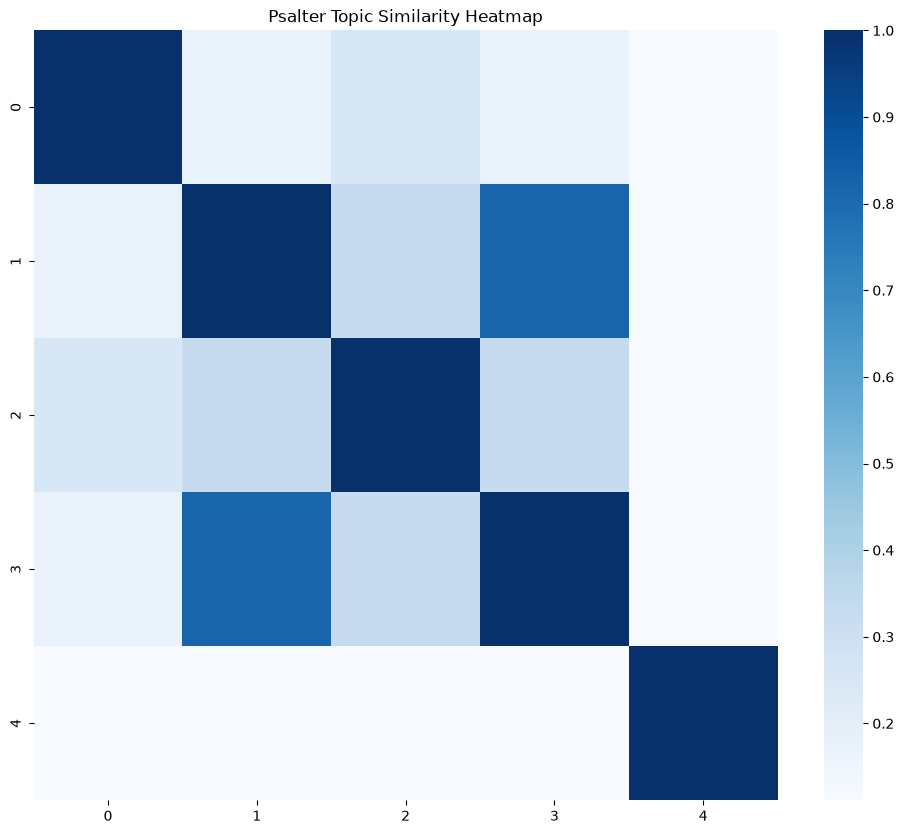

In [51]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

topic_ids = list(psalter_topic_sets.keys())

matrix = pd.DataFrame(
    index=topic_ids,
    columns=topic_ids
)

for t1 in topic_ids:
    for t2 in topic_ids:
        intersection = len(topic_sets[t1] & topic_sets[t2])
        union = len(topic_sets[t1] | topic_sets[t2])

        matrix.loc[t1, t2] = intersection / union

matrix = matrix.astype(float)

plt.figure(figsize=(12,10))
sns.heatmap(matrix, cmap="Blues")
plt.title("Psalter Topic Similarity Heatmap")
plt.show()

topic5_psalter_matrix = matrix

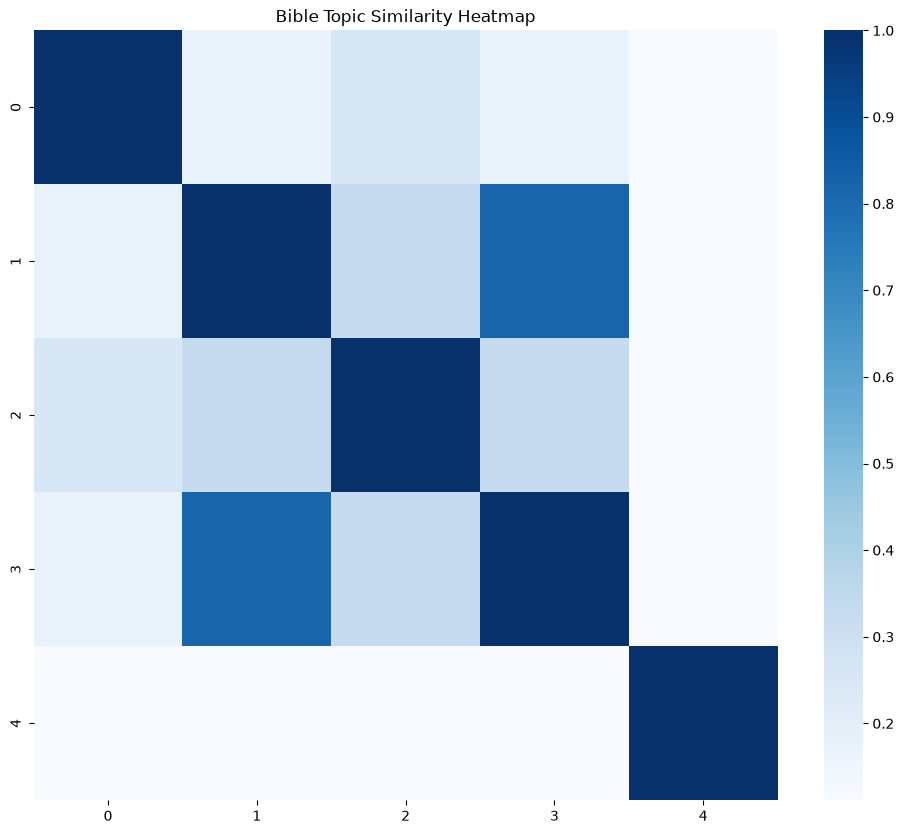

In [52]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

topic_ids = list(bible_topic_sets.keys())

matrix = pd.DataFrame(
    index=topic_ids,
    columns=topic_ids
)

for t1 in topic_ids:
    for t2 in topic_ids:
        intersection = len(topic_sets[t1] & topic_sets[t2])
        union = len(topic_sets[t1] | topic_sets[t2])

        matrix.loc[t1, t2] = intersection / union

matrix = matrix.astype(float)

plt.figure(figsize=(12,10))
sns.heatmap(matrix, cmap="Blues")
plt.title("Bible Topic Similarity Heatmap")
plt.show()


topic5_bible_matrix = matrix

In [53]:
rows = []

for topic_id, words in psalter_topic_sets.items():
    for word in words:
        rows.append({
            "topic_id": topic_id,
            "Psalter - word": word
        })

df_topics = pd.DataFrame(rows)

# df_topics

In [54]:
rows = []

for topic_id, words in bible_topic_sets.items():
    for word in words:
        rows.append({
            "topic_id": topic_id,
            "Bible - word": word
        })

bible_df_topics = pd.DataFrame(rows)

#bible_df_topics

In [55]:
overall_topics5 = pd.concat([bible_df_topics, df_topics], axis=1, join='inner').T.drop_duplicates().T

#overall_topics

In [56]:
duplicates_per_topic = [0,0,0,0,0]

for i in [0, 10, 20, 30, 40]:
    target_word = overall_topics5['Bible - word'].iloc[i]
    #print(target_word)
    # comparing to each word in the paticular psalter topi
    for j in range(10):
        compare_word = overall_topics5['Psalter - word'].iloc[j+i]
        if target_word == compare_word: 
            # found a duplicate and recordings in the ith topic's position of the array
            duplicates_per_topic[int(i/10)] += 1
        #print(f"   {compare_word}")

print(duplicates_per_topic)

[0, 1, 0, 1, 0]




    duplicates_per_topic = [0,0,0,0,0]

    for i in [0, 10, 20, 30, 40]:
        print(f"Topic {i/10}")
        for i in range(i, i+10):
            target_word = overall_topics['Bible - word'].iloc[i]
            print(target_word)
            # comparing to each word in the paticular psalter topic
            for j in range(10):
                compare_word = overall_topics['Psalter - word'].iloc[j+i]
                if target_word == compare_word: 
                    # found a duplicate and recordings in the ith topic's position of the array
                    duplicates_per_topic[int(i/10)] += 1
                #print(f"   {compare_word}")

    print(duplicates_per_topic

In [57]:
duplicates_per_topic = [0, 0, 0, 0, 0]

for topic_start in [0, 10, 20, 30, 40]:
    topic_num = topic_start // 10

    print(f"Topic {topic_num}")

    for bible_idx in range(topic_start, topic_start + 10):
        target_word = overall_topics5['Bible - word'].iloc[bible_idx]

        for psalter_idx in range(topic_start, topic_start + 10):
            compare_word = overall_topics5['Psalter - word'].iloc[psalter_idx]

            if target_word == compare_word:
                duplicates_per_topic[topic_num] += 1

print(duplicates_per_topic)

Topic 0
Topic 1
Topic 2
Topic 3
Topic 4
[3, 9, 7, 5, 3]


In [58]:
rows = []

for i in range(len(duplicates_per_topic)):
    rows.append({
        "Topic": i,
        "Percentage of Duplicates": duplicates_per_topic[i] / 10
    })
    
dup_percentages = pd.DataFrame(rows)
dup_percentages_5 = dup_percentages

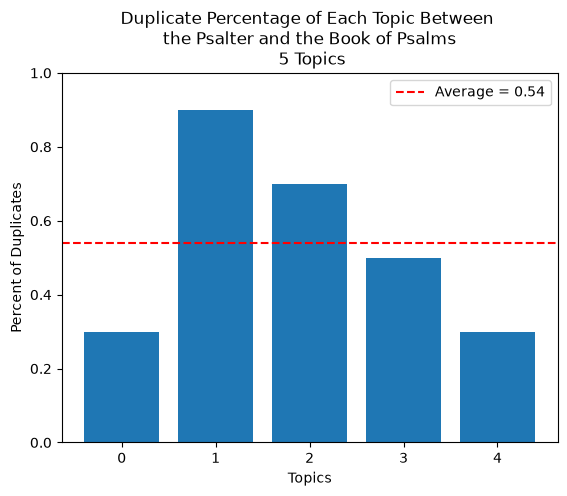

In [59]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ax.bar(
    dup_percentages["Topic"],
    dup_percentages["Percentage of Duplicates"]
)

ax.set_ylim(0, 1)

avg = dup_percentages["Percentage of Duplicates"].mean()

ax.axhline(avg, color='red', linestyle='--', label=f'Average = {avg:.2f}')

ax.set_xlabel('Topics')
ax.set_ylabel('Percent of Duplicates')
ax.set_title('Duplicate Percentage of Each Topic Between \n the Psalter and the Book of Psalms \n 5 Topics')

ax.set_xticks(dup_percentages["Topic"])

ax.legend()

# IMPORTANT: save figure object
topic5_duplicate_plot = fig

plt.show()

# Invesitgating Thematic Overlapp -- 5 Topics

In [60]:

from bertopic import BERTopic
from sklearn.cluster import KMeans
import pandas as pd

def create_topic_model(n_topics=10):

    cluster_model = KMeans(
        n_clusters=n_topics,
        random_state=42,
        n_init=10
    )

    model = BERTopic(
        hdbscan_model=cluster_model,
        verbose=True
    )

    return model


In [61]:

# Clean and prepare Bible and Psalter texts
bible_texts = (
    bible['cleaned_verse']
    .fillna('')
    .astype(str)
    .tolist()
)

psalter_texts = (
    psalter['cleaned_verse']
    .fillna('')
    .astype(str)
    .tolist()
)


In [62]:

# Create independent models
bible_model = create_topic_model(n_topics=5)
psalter_model = create_topic_model(n_topics=5)

# Fit Bible model
bible_topics, bible_probs = bible_model.fit_transform(bible_texts)

# Fit Psalter model
psalter_topics, psalter_probs = psalter_model.fit_transform(psalter_texts)

# Store topic assignments
bible['topic_10'] = bible_topics
psalter['topic_10'] = psalter_topics


2026-11-21 16:16:53,452 - BERTopic - Embedding - Transforming documents to embeddings.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

2026-11-21 16:16:55,895 - BERTopic - Embedding - Completed ✓
2026-11-21 16:16:55,895 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-21 16:16:57,620 - BERTopic - Dimensionality - Completed ✓
2026-11-21 16:16:57,620 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-21 16:16:57,631 - BERTopic - Cluster - Completed ✓
2026-11-21 16:16:57,633 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-21 16:16:57,648 - BERTopic - Representation - Completed ✓
2026-11-21 16:16:57,664 - BERTopic - Embedding - Transforming documents to embeddings.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

2026-11-21 16:17:00,833 - BERTopic - Embedding - Completed ✓
2026-11-21 16:17:00,834 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-21 16:17:02,587 - BERTopic - Dimensionality - Completed ✓
2026-11-21 16:17:02,587 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-21 16:17:02,597 - BERTopic - Cluster - Completed ✓
2026-11-21 16:17:02,599 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-21 16:17:02,616 - BERTopic - Representation - Completed ✓


In [63]:
# Bible topic information
bible_topic_info = bible_model.get_topic_info()

# Psalter topic information
psalter_topic_info = psalter_model.get_topic_info()

display(bible_topic_info)
display(psalter_topic_info)

Topic  Count                              Name  \
0      0     57              0_shall_lord_god_let   
1      1     30              1_god_lord_shall_end   
2      2     29            2_god_lord_shall_earth   
3      3     22  3_lord_forever_shall_commandment   
4      4     13           4_lord_onean_ascent_ode   

                                                                       Representation  \
0                          [shall, lord, god, let, hand, soul, like, man, day, heart]   
1                 [god, lord, shall, end, david, man, may, heart, lawlessness, mercy]   
2                    [god, lord, shall, earth, let, people, psalm, king, sing, pause]   
3  [lord, forever, shall, commandment, praise, mercy, endures, give, ordinance, word]   
4                   [lord, onean, ascent, ode, like, shall, israel, let, soul, house]   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

Topic  Count                    Name  \
0      0     44     0_lord_thou_thy_god   
1      1     34      1_me_lord_thou_thy   
2      2     28    2_shall_god_lord_thy   
3      3     27     3_thy_shall_lord_me   
4      4     17  4_lord_praise_ye_earth   

                                                       Representation  \
0        [lord, thou, thy, god, shall, unto, ever, hast, hath, mercy]   
1            [me, lord, thou, thy, unto, thee, shall, god, let, hast]   
2        [shall, god, lord, thy, thou, unto, earth, thee, upon, hath]   
3   [thy, shall, lord, me, thou, word, heart, commandment, thee, law]   
4  [lord, praise, ye, earth, shall, glory, unto, heaven, him, people]   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         

In [64]:

from collections import defaultdict

bible_topics = defaultdict(dict)
psalter_topics = defaultdict(dict)

# Extract Bible topic words and weights
for topic_id in bible_model.get_topic_info()['Topic']:

    words = bible_model.get_topic(topic_id)

    if words:
        for word, weight in words:
            bible_topics[topic_id][word] = weight


# Extract Psalter topic words and weights
for topic_id in psalter_model.get_topic_info()['Topic']:

    words = psalter_model.get_topic(topic_id)

    if words:
        for word, weight in words:
            psalter_topics[topic_id][word] = weight


In [65]:
from collections import defaultdict

all_vocab = set()

for d in bible_topics.values():
    all_vocab.update(d.keys())

for d in psalter_topics.values():
    all_vocab.update(d.keys())

all_vocab = list(all_vocab)


In [66]:
def to_vector(d):
    return [d.get(w, 0.0) for w in all_vocab]

In [67]:
def normalize(topic_dict):
    total = sum(topic_dict.values())
    return {w: v / total for w, v in topic_dict.items()}

In [68]:
bible_topics = {k: normalize(v) for k, v in bible_topics.items()}
psalter_topics = {k: normalize(v) for k, v in psalter_topics.items()}

In [69]:
from math import sqrt

def cosine_dict(a, b):
    # union is optional but safer
    keys = set(a) | set(b)

    dot = sum(a.get(k, 0) * b.get(k, 0) for k in keys)
    norm_a = sqrt(sum(v*v for v in a.values()))
    norm_b = sqrt(sum(v*v for v in b.values()))

    if norm_a == 0 or norm_b == 0:
        return 0

    return dot / (norm_a * norm_b)

In [70]:
matrix = []
for b_id, b_vec in bible_topics.items():
    row = []
    for p_id, p_vec in psalter_topics.items():

        # print("B sample:", list(b_vec.items())[:3])
        # print("P sample:", list(p_vec.items())[:3])

        val = cosine_dict(b_vec, p_vec)

        # print("cosine:", val)
        # print("----")

        row.append(val)

    matrix.append(row)
    
    
matrix_5 = matrix.copy()
    
#matrix

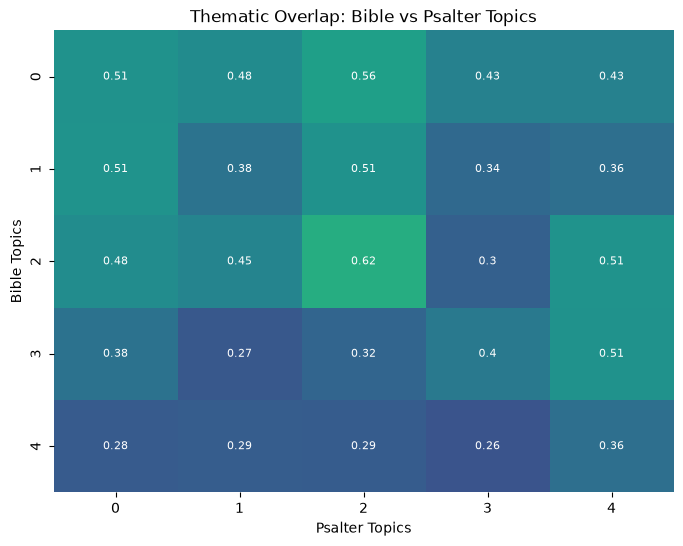

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    matrix_5,
    annot=True,
    cmap="viridis",
    annot_kws={'size': 8},
    vmin=0,
    vmax=1,
    cbar=False,
    ax=ax
)

ax.set_title("Thematic Overlap: Bible vs Psalter Topics")
ax.set_xlabel("Psalter Topics")
ax.set_ylabel("Bible Topics")

plt.show()

## 10 Topics

In [72]:
cluster_model = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

topic_model = BERTopic(
    hdbscan_model=cluster_model
)
'''
bible_topics, bible_probs = bible_topic_model.fit_transform(
    bible["cleaned_verse"].fillna("").astype(str).tolist()
)

psalter_topics10, psalter_probs = topic_model.fit_transform(psalter['cleaned_verse'])

topic_model.get_topic_info()'''

'\nbible_topics, bible_probs = bible_topic_model.fit_transform(\n    bible["cleaned_verse"].fillna("").astype(str).tolist()\n)\n\npsalter_topics10, psalter_probs = topic_model.fit_transform(psalter[\'cleaned_verse\'])\n\ntopic_model.get_topic_info()'

In [73]:
print(topic_model.hdbscan_model.n_clusters)
print(topic_model.hdbscan_model.n_clusters)

10
10


### Bible

In [74]:
bible_topics10, bible_probs = topic_model.fit_transform(bible['cleaned_verse'])

topic_model.get_topic_info()

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Topic  Count                                Name  \
0      0     23                0_lord_god_end_shall   
1      1     22                1_shall_god_let_lord   
2      2     19             2_god_shall_earth_pause   
3      3     16               3_lord_soul_shall_eye   
4      4     15             4_lord_shall_david_hand   
5      5     13              5_lord_shall_earth_god   
6      6     13             6_onean_ascent_lord_ode   
7      7     12        7_praise_lord_alleluia_shall   
8      8     10  8_lord_commandment_forever_endures   
9      9      8      9_god_shall_inscription_pillar   

                                                                        Representation  \
0                        [lord, god, end, shall, david, man, may, heart, psalm, enemy]   
1                           [shall, god, let, lord, like, day, man, hand, poor, earth]   
2                 [god, shall, earth, pause, psalm, end, lord, troubled, people, sing]   
3                         [lord, soul, shall, eye, heart, way, david, sin, god, mercy]   
4                     [lord, shall, david, hand, bless, soul, work, mercy, fear, hope]   
5                    [lord, shall, earth, god, let, glory, people, king, voice, psalm]   
6                   [onean, ascent, lord, ode, israel, like, shall, let, would, house]   
7              [praise, lord, alleluia, shall, age, name, heaven, people, earth, unto]   
8  [lord, commandment, forever, endures, mercy, law, ordinance, give, word, testimony]   
9            [god, shall, inscription, pillar, onefor, end, king, right, hand, people]   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      

In [75]:
bible['topic_10'] = bible_topics10 # adding to df for later exploration

In [76]:
bible10_topic_words = get_topic_words(topic_model)

In [77]:
topic_words = topic_model.get_topics()

# topic_words

In [78]:
bible_topic10_sets = {}

for topic_id, words_scores in topic_words.items():
    if topic_id == -1:
        continue

    bible_topic10_sets[topic_id] = {
        word: score for word, score in words_scores[:10]
    }
#bible_topic_sets

In [79]:
rows = []

for topic_id, word_dict in bible_topic10_sets.items():
    for word, score in word_dict.items():
        rows.append({
            "topic_id": topic_id,
            "Bible - word": word,
            "Weight": score
        })

bible_df_topics10 = pd.DataFrame(rows)

bible_df_topics10

,topic_id,Bible - word,Weight
0,0,lord,0.058299
1,0,god,0.053114
2,0,end,0.044135
3,0,shall,0.037196
4,0,david,0.036609
...,...,...,...
95,9,end,0.028459
96,9,king,0.027372
97,9,right,0.026314
98,9,hand,0.026120


### Psalter

In [80]:
psalter_topics10, psalter_probs = topic_model.fit_transform(psalter['cleaned_verse'])

topic_model.get_topic_info()

Topic  Count                        Name  \
0      0     21  0_lord_ever_mercy_endureth   
1      1     21      1_lord_shall_unto_zion   
2      2     20         2_thy_shall_me_lord   
3      3     19          3_me_thy_thou_thee   
4      4     17        4_me_lord_shall_thou   
5      5     14         5_thou_me_thee_unto   
6      6     14      6_lord_praise_ye_earth   
7      7     11        7_god_thy_thou_shall   
8      8      8   8_god_tabernacle_thy_thou   
9      9      5       9_god_thou_shall_hast   

                                                        Representation  \
0    [lord, ever, mercy, endureth, thy, shall, thou, work, hath, hast]   
1  [lord, shall, unto, zion, god, thee, earth, israel, blessed, house]   
2       [thy, shall, me, lord, thou, word, commandment, law, way, let]   
3             [me, thy, thou, thee, unto, god, lord, shall, hast, day]   
4             [me, lord, shall, thou, let, unto, thee, god, upon, him]   
5            [thou, me, thee, unto, thy, god, lord, hath, shall, soul]   
6    [lord, praise, ye, earth, glory, people, sing, unto, shall, king]   
7     [god, thy, thou, shall, earth, mountain, unto, lord, thee, hast]   
8      [god, tabernacle, thy, thou, hast, lord, shall, hath, me, mine]   
9  [god, thou, shall, hast, heart, people, long, lord, iniquity, said]   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

In [81]:
psalter['topic_10'] = 0

psalter['topic_10'] = psalter_topics10
psalter

,Unnamed: 0,tradition,text,psalm_num,verse,cleaned_verse,topic,topic_10
151,151,Orthodox,Psalter,1,"Blessed is the man that hath not walked in the counsel of the ungodly, nor stood in the way of sinners, nor sat in the seat of the pestilent. But his will is in the law of the Lord, and in His law shall he meditate day and night. And he shall be like the tree planted by the streams of waters, that shall bring forth his fruit in his season; his leaf also shall not fall, and whatsoever he doeth shall prosper. The ungodly are not so, not so: but are like the chaff which the wind driveth away from the face of the earth. Therefore the ungodly shall not rise up in the judgment, nor sinners in the congregation of the righteous. For the Lord knoweth the way of the righteous; but the way of the ungodly shall perish.","blessed man hath walked counsel ungodly , stood way sinner , sat seat pestilent . law lord , law shall meditate day night . shall like tree planted stream water , shall bring forth fruit season ; leaf also shall fall , whatsoever doeth shall prosper . ungodly so , so : like chaff wind driveth away face earth . therefore ungodly shall rise judgment , sinner congregation righteous . lord knoweth way righteous ; way ungodly shall perish .",0,2
152,152,Orthodox,Psalter,2,"Why did the heathen rage, and the peoples imagine vain things? The kings of the earth stood up, and the rulers were gathered together, against the Lord and against His Christ, saying, Let us break their bands asunder, and cast away their yoke from us. He that dwelleth in the heavens shall laugh them to scorn, and the Lord shall have them in derision. Then shall He speak to them in His wrath, and vex them in His sore displeasure. But I was established King by Him upon His holy mount of Zion, declaring the decree of the Lord. The Lord hath said unto me, Thou art My Son; this day have I begotten Thee. Ask of Me, and I shall give Thee the heathen for Thine inheritance, and the uttermost parts of the earth for Thy possession. Thou shalt shepherd them with a rod of iron; Thou shalt dash them in pieces like a potter's vessels. Be wise now therefore, O ye kings; be instructed, all ye judges of the earth. Serve the Lord with fear, and rejoice in Him with trembling. Embrace instruction, lest the Lord be angry, and ye perish from the righteous way, when His wrath is kindled suddenly. Blessed are all they that put their trust in Him.","heathen rage , people imagine vain thing ? king earth stood up , ruler gathered together , lord christ , saying , let u break band asunder , cast away yoke u . dwelleth heaven shall laugh scorn , lord shall derision . shall speak wrath , vex sore displeasure . established king upon holy mount zion , declaring decree lord . lord hath said unto me , thou art son ; day begotten thee . ask me , shall give thee heathen thine inheritance , uttermost part earth thy possession . thou shalt shepherd rod iron ; thou shalt dash piece like potter 's vessel . wise therefore , ye king ; instructed , ye judge earth . serve lord fear , rejoice trembling . embrace instruction , lest lord angry , ye perish righteous way , wrath kindled suddenly . blessed put trust him .",3,7
153,153,Orthodox,Psalter,3,"Lord, why are they increased that trouble me? many are they that rise up against me. Many there be which say to my soul, There is no salvation for him in his God. But Thou, O Lord, art my helper, my glory, and the lifter up of mine head. I cried unto the Lord with my voice, and He heard me out of His holy mount. I laid me down and slept; I arose, for the Lord will help me. I will not be afraid of ten thousands of people, that have set themselves against me round about. Arise, O Lord; save me, O my God: for Thou hast smitten all them that are mine enemies without a cause; Thou hast broken the teeth of sinners. Salvation is of the Lord, and Thy blessing is upon Thy people.","lord , increased trouble me ? many rise me . many say soul , salvation god . thou , lord

In [82]:
psalter10_topic_words = get_topic_words(topic_model)

In [83]:
psalter_topic_words = topic_model.get_topics()

# topic_words

In [84]:
psalter_topic_sets = {}

for topic_id, words_scores in psalter_topic_words.items():
    if topic_id == -1:
        continue

    psalter_topic_sets[topic_id] = {
        word: score for word, score in words_scores[:10]
    }
#psalter_topic_sets

In [85]:
rows = []

for topic_id, words in psalter_topic_sets.items():
    for word, score in words.items():
        rows.append({
            "topic_id": topic_id,
            "Psalter - word": word,
            "Psalter Weight": score
        })
df_topics10_psalter = pd.DataFrame(rows)

df_topics10_psalter.head(20)

,topic_id,Psalter - word,Psalter Weight
0,0,lord,0.060137
1,0,ever,0.056550
2,0,mercy,0.051372
3,0,endureth,0.043723
4,0,thy,0.037553
5,0,shall,0.035714
6,0,thou,0.034415
7,0,work,0.032996
8,0,hath,0.031561
9,0,hast,0.030096


In [86]:
bible_df_topics10

,topic_id,Bible - word,Weight
0,0,lord,0.058299
1,0,god,0.053114
2,0,end,0.044135
3,0,shall,0.037196
4,0,david,0.036609
...,...,...,...
95,9,end,0.028459
96,9,king,0.027372
97,9,right,0.026314
98,9,hand,0.026120


## Combining the Data

In [87]:
overall_topics = pd.concat([bible_df_topics10, df_topics10_psalter], axis=1, join='outer').T.drop_duplicates().T

overall_topics

,topic_id,Bible - word,Weight,Psalter - word,Psalter Weight
0,0,lord,0.058299,lord,0.060137
1,0,god,0.053114,ever,0.05655
2,0,end,0.044135,mercy,0.051372
3,0,shall,0.037196,endureth,0.043723
4,0,david,0.036609,thy,0.037553
...,...,...,...,...,...
95,9,end,0.028459,people,0.041771
96,9,king,0.027372,long,0.039792
97,9,right,0.026314,lord,0.036662
98,9,hand,0.02612,iniquity,0.034899


In [88]:
duplicates_per_topic = []

for topic_start in range(0, 100, 10):
    bible_words = set(
        overall_topics['Bible - word'].iloc[topic_start:topic_start+10]
    )

    psalter_words = set(
        overall_topics['Psalter - word'].iloc[topic_start:topic_start+10]
    )

    duplicates_per_topic.append(len(bible_words & psalter_words))

print(duplicates_per_topic)

[2, 4, 2, 3, 2, 3, 2, 4, 1, 3]


In [89]:
rows = []

for i in range(len(duplicates_per_topic)):
    rows.append({
        "Topic": i,
        "Percentage of Duplicates": duplicates_per_topic[i] / 10
    })
    
dup_percentages = pd.DataFrame(rows)
dup_percentages

,Topic,Percentage of Duplicates
0,0,0.2
1,1,0.4
2,2,0.2
3,3,0.3
4,4,0.2
5,5,0.3
6,6,0.2
7,7,0.4
8,8,0.1
9,9,0.3


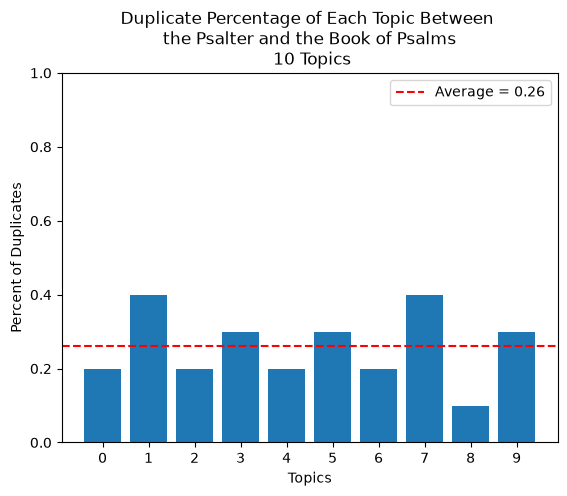

In [90]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ax.bar(
    dup_percentages["Topic"],
    dup_percentages["Percentage of Duplicates"]
)

ax.set_ylim(0, 1)

avg = dup_percentages["Percentage of Duplicates"].mean()

ax.axhline(avg, color='red', linestyle='--', label=f'Average = {avg:.2f}')

ax.set_xlabel('Topics')
ax.set_ylabel('Percent of Duplicates')
ax.set_title('Duplicate Percentage of Each Topic Between \n the Psalter and the Book of Psalms \n 10 Topics')

ax.set_xticks(dup_percentages["Topic"])

ax.legend()

# IMPORTANT: save figure object
topic10_duplicate_plot = fig

plt.show()

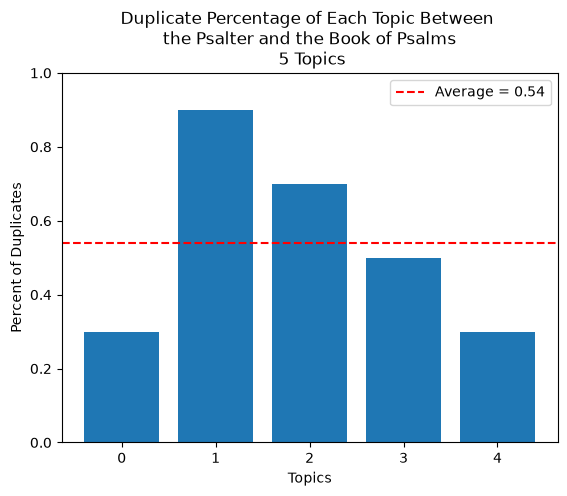

In [91]:
topic5_duplicate_plot

In [92]:
overall_topics.head(15)

,topic_id,Bible - word,Weight,Psalter - word,Psalter Weight
0,0,lord,0.058299,lord,0.060137
1,0,god,0.053114,ever,0.05655
2,0,end,0.044135,mercy,0.051372
3,0,shall,0.037196,endureth,0.043723
4,0,david,0.036609,thy,0.037553
5,0,man,0.036303,shall,0.035714
6,0,may,0.034974,thou,0.034415
7,0,heart,0.034036,work,0.032996
8,0,psalm,0.028414,hath,0.031561
9,0,enemy,0.025533,hast,0.030096


# Invesitgating Thematic Overlapp

In [93]:
bible_topics = defaultdict(dict)
psalter_topics = defaultdict(dict)

for _, row in overall_topics.iterrows():
    t = row["topic_id"]

    w1 = row["Bible - word"]
    w2 = row["Psalter - word"]

    bible_topics[t][w1] = max(bible_topics[t].get(w1, 0), row["Weight"])
    psalter_topics[t][w2] = max(psalter_topics[t].get(w2, 0), row["Psalter Weight"])

In [94]:
from collections import defaultdict

all_vocab = set()

for d in bible_topics.values():
    all_vocab.update(d.keys())

for d in psalter_topics.values():
    all_vocab.update(d.keys())

all_vocab = list(all_vocab)


In [95]:
def to_vector(d):
    return [d.get(w, 0.0) for w in all_vocab]

In [96]:
def normalize(topic_dict):
    total = sum(topic_dict.values())
    return {w: v / total for w, v in topic_dict.items()}

In [97]:
bible_topics = {k: normalize(v) for k, v in bible_topics.items()}
psalter_topics = {k: normalize(v) for k, v in psalter_topics.items()}

In [98]:
from math import sqrt

def cosine_dict(a, b):
    # union is optional but safer
    keys = set(a) | set(b)

    dot = sum(a.get(k, 0) * b.get(k, 0) for k in keys)
    norm_a = sqrt(sum(v*v for v in a.values()))
    norm_b = sqrt(sum(v*v for v in b.values()))

    if norm_a == 0 or norm_b == 0:
        return 0

    return dot / (norm_a * norm_b)

In [99]:
matrix = []
for b_id, b_vec in bible_topics.items():
    row = []
    for p_id, p_vec in psalter_topics.items():

        # print("B sample:", list(b_vec.items())[:3])
        # print("P sample:", list(p_vec.items())[:3])

        val = cosine_dict(b_vec, p_vec)

        # print("cosine:", val)
        # print("----")

        row.append(val)

    matrix.append(row)
    
matrix_10 = matrix.copy()
#matrix

## Graphing Tematic Overlapp

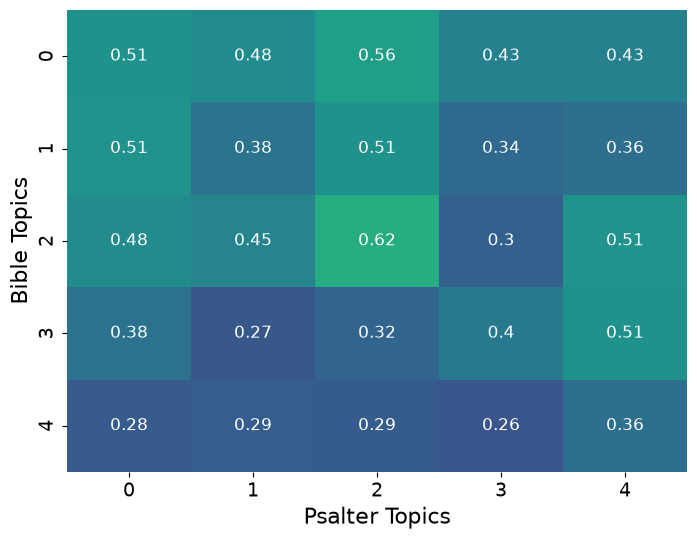

In [100]:
'''=== 5 Topics ==='''

import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    matrix_5,
    annot=True,
    cmap="viridis",
    annot_kws={'size': 12},
    vmin=0,
    vmax=1,
    cbar=False,
    ax=ax
)

# 
# ax.set_title("Thematic Overlap: Bible vs Psalter for 10 Topics")
ax.set_xlabel("Psalter Topics", fontsize=16)
ax.set_ylabel("Bible Topics", fontsize=16)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)

plt.show()

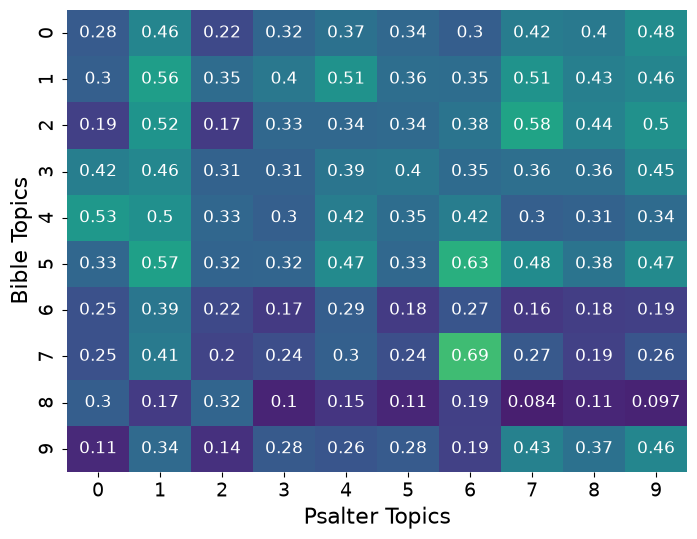

In [101]:
'''=== 10 Topics ==='''

import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    matrix,
    annot=True,
    cmap="viridis",
    annot_kws={'size': 12},
    vmin=0,
    vmax=1,
    cbar=False,
    ax=ax
)
# 
# ax.set_title("Thematic Overlap: Bible vs Psalter for 10 Topics")
ax.set_xlabel("Psalter Topics", fontsize=16)
ax.set_ylabel("Bible Topics", fontsize=16)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)

plt.show()

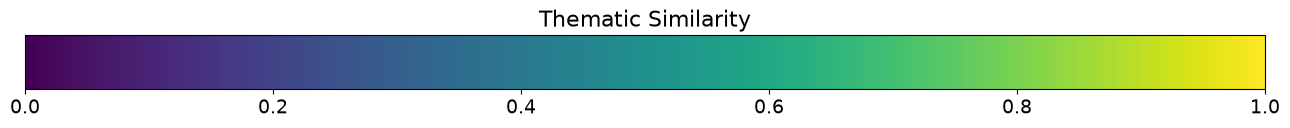

In [102]:
import matplotlib as mpl
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(16, 0.7))

norm = mpl.colors.Normalize(vmin=0, vmax=1)

cbar = fig.colorbar(
    mpl.cm.ScalarMappable(norm=norm, cmap="viridis"),
    cax=ax,
    orientation="horizontal", 
)

ax.set_title("Thematic Similarity", fontsize=16)
cbar.ax.tick_params(labelsize=14)

plt.show()

# Totals  of topic distrobutions

In [103]:
psalter = psalter.rename(columns={'topic': 'topic_5'})
psalter['topic_5'].value_counts()

topic_5
 0    63
 1    37
-1    24
 3    22
 4     4
Name: count, dtype: int64

In [104]:
bible = bible.rename(columns={'topic': 'topic_5'})

bible['topic_5'].value_counts()

topic_5
 2    63
-1    29
 1    27
 3    14
 0    10
 4     8
Name: count, dtype: int64

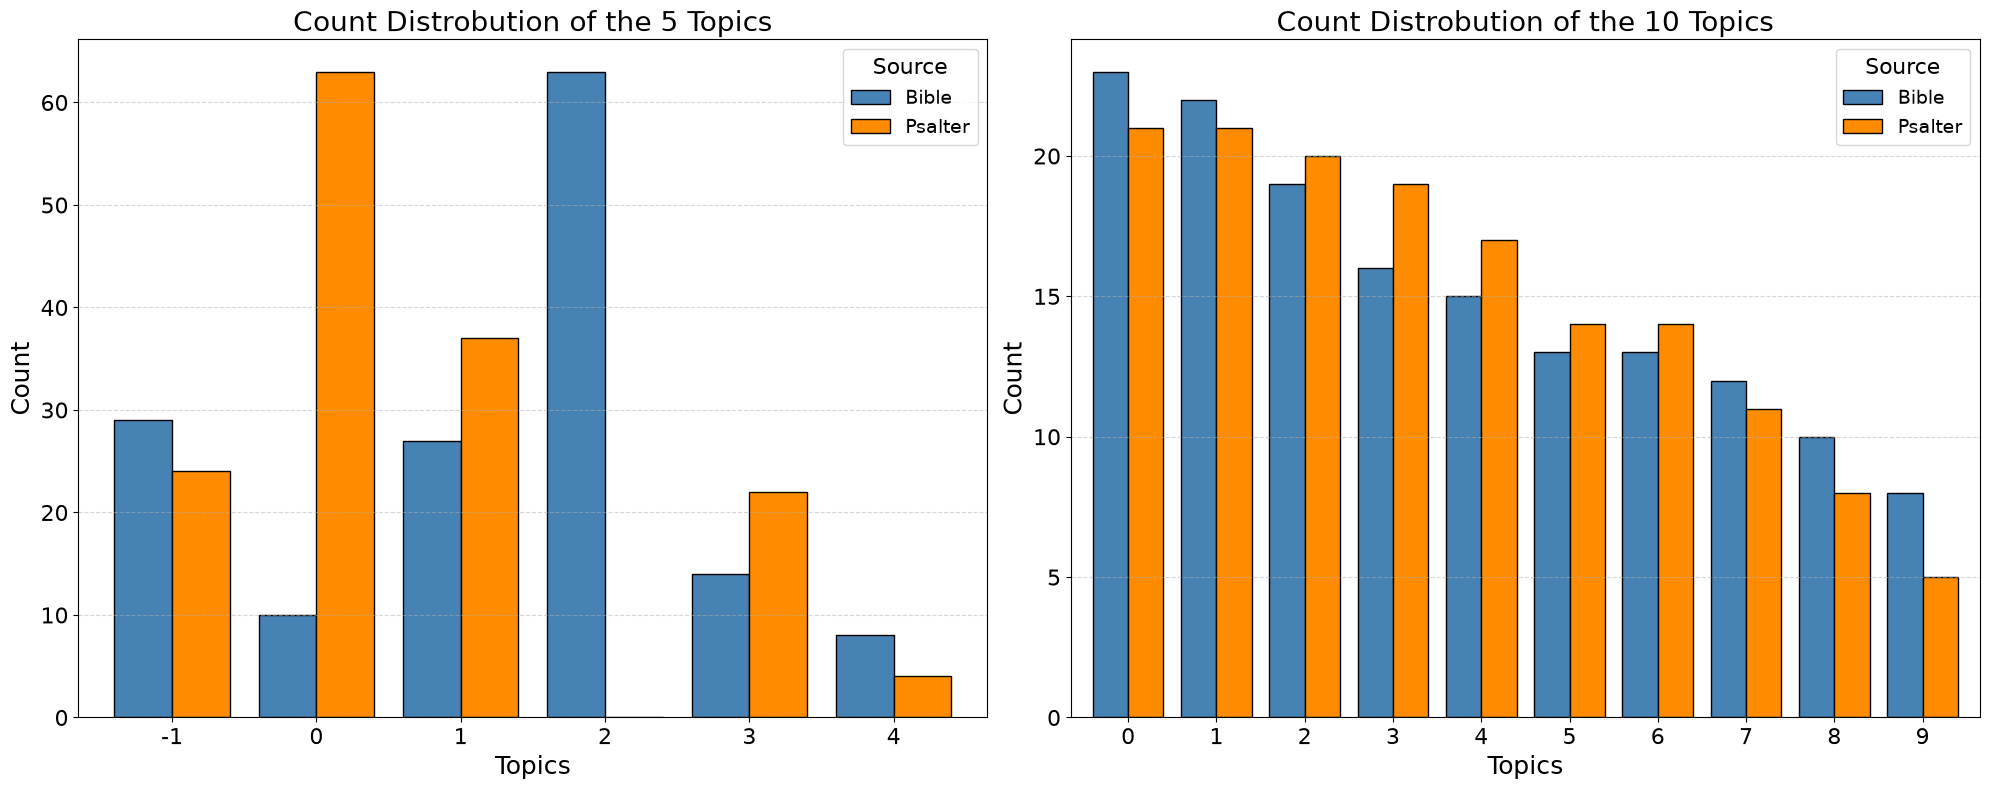

In [105]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Combine datasets
bible['source'] = 'Bible'
psalter['source'] = 'Psalter'

data = pd.concat([bible, psalter], ignore_index=True)

# Create side-by-side graphs
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Consistent colors
colors = {'Bible': 'steelblue', 'Psalter': 'darkorange'}

# Loop through topic columns
for ax, topic in zip(axes, ['topic_5', 'topic_10']):

    # Count each topic by source
    counts = data.groupby([topic, 'source']).size().unstack(fill_value=0)

    # Plot grouped bars
    counts.plot(
        kind='bar',
        ax=ax,
        color=colors,
        edgecolor='black',
        width=0.8
    )
    
    n = 5 if topic == 'topic_5' else 10

    # Titles and labels
    ax.set_title(f'Count Distrobution of the {n} Topics', fontsize=20)
    ax.set_xlabel('Topics', fontsize=18)
    ax.set_ylabel('Count', fontsize=18)

    # Font sizes
    ax.tick_params(axis='both', labelsize=16)
    ax.tick_params(axis='x', rotation=0)

    # Legend
    ax.legend(title='Source', fontsize=14, title_fontsize=16)

    # Grid
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [106]:

pd.pivot_table(
    data=data,
    index=['source', 'topic_5'],
    aggfunc='size'
).reset_index(name='count')

,source,topic_5,count
0,Bible,-1,29
1,Bible,0,10
2,Bible,1,27
3,Bible,2,63
4,Bible,3,14
5,Bible,4,8
6,Psalter,-1,24
7,Psalter,0,63
8,Psalter,1,37
9,Psalter,3,22


# different work:

# Inveistigation POS of Topics Per source

In [107]:
import nltk
from nltk.tokenize import word_tokenize

# Dictionary mapping standard NLTK codes to full words
TAG_MAP = {
    # --- NOUNS ---
    'NN': 'noun', 'NNS': 'noun', 'NNP': 'proper noun', 'NNPS': 'proper noun',
    
    # --- VERBS ---
    'VB': 'verb', 'VBD': 'verb', 'VBG': 'verb', 'VBN': 'verb', 
    'VBP': 'verb', 'VBZ': 'verb', 'MD': 'verb',
    
    # --- ADJECTIVES ---
    'JJ': 'adjective', 'JJR': 'adjective', 'JJS': 'adjective',
    
    # --- ADVERBS ---
    'RB': 'adverb', 'RBR': 'adverb', 'RBS': 'adverb', 'WRB': 'adverb',
    
    # --- PRONOUNS ---
    'PRP': 'pronoun', 'PRP$': 'pronoun', 'WP': 'pronoun', 'WP$': 'pronoun',
    
    # --- DETERMINERS ---
    'DT': 'determiner', 'WDT': 'determiner', 'PDT': 'determiner',
    
    # --- CONJUNCTIONS & PREPOSITIONS ---
    'CC': 'conjunction', 'IN': 'preposition',
    
    # --- OTHER WORDS ---
    'CD': 'number', 'UH': 'interjection', 'FW': 'foreign word',
    'EX': 'existential', 'RP': 'particle', 'TO': 'to', 'LS': 'marker',
    
    # --- PUNCTUATION & SYMBOLS ---
    '.': 'punctuation', ',': 'punctuation', ':': 'punctuation',
    '(': 'punctuation', ')': 'punctuation', '``': 'punctuation', 
    "''": 'punctuation', '$': 'symbol', '#': 'symbol', 'SYM': 'symbol',
    'POS': 'symbol'
}


def tag_word(word):
    token = word_tokenize(word)
    # Get the raw tag (e.g., 'NN' or 'JJ')
    raw_tag = nltk.pos_tag(token)[0][1]
    
    # Return the mapped name, or 'other' if it isn't a noun or adjective
    return TAG_MAP.get(raw_tag, 'other')

# Examples
print(tag_word("apple"))  # Output: noun
print(tag_word("quick"))  # Output: adjective
print(tag_word("run"))    # Output: other


noun
noun
verb


In [108]:
tag_word("the")

'determiner'

In [109]:
overall_topics['Psalter Topic POS'] = overall_topics["Psalter - word"].apply(tag_word)


overall_topics['Bible Topic POS'] = overall_topics["Bible - word"].apply(tag_word)

#overall_topics

In [110]:
overall_topics.groupby('Psalter Topic POS').size()

Psalter Topic POS
adverb          2
noun           76
preposition     1
pronoun         6
verb           15
dtype: int64

In [111]:
overall_topics.groupby('Bible Topic POS').size()

Bible Topic POS
adjective       2
adverb          1
noun           79
preposition     2
verb           16
dtype: int64

Not much of a difference, overall

In [112]:
psalter_pos_df = overall_topics.groupby(['topic_id', 'Psalter Topic POS']).size().reset_index(name='count')
#psalter_pos_df

In [113]:
bible_pos_df = overall_topics.groupby(['topic_id', 'Bible Topic POS']).size().reset_index(name='count')
#bible_pos_df

In [114]:
# Map each POS to a specific hex color code
POS_COLORS = {
    'noun': '#1f77b4',         # Classic Blue
    'verb': '#ff7f0e',         # Energetic Orange
    'preposition': '#2ca02c',  # Sage Green
    'adverb': '#d62728',        # Muted Red
    'pronoun': '#9467bd'       # Distinct Purple
}

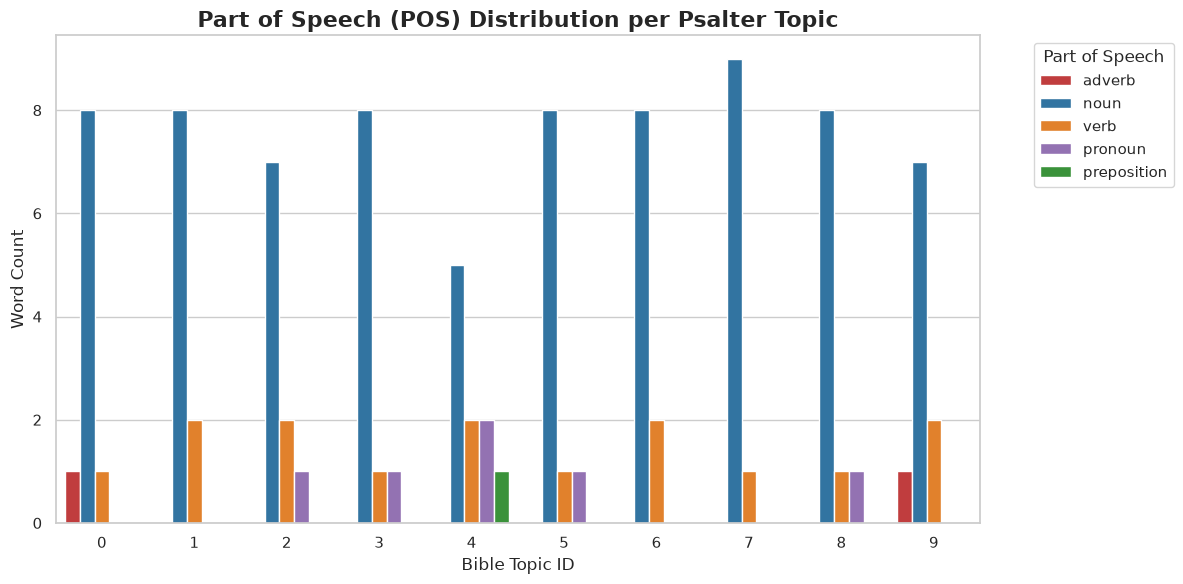

In [122]:
# 2. Set the plot size and style
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# 3. Create a grouped bar chart
# 'hue' splits the bars into individual colors for each Part of Speech (POS)
sns.barplot(data=psalter_pos_df, x="topic_id", y="count", hue="Psalter Topic POS", palette=POS_COLORS)

# 4. Add titles and clean up labels
plt.title(
    "Part of Speech (POS) Distribution per Psalter Topic",
    fontsize=16,
    fontweight="bold",
)
plt.xlabel("Bible Topic ID", fontsize=12)
plt.ylabel("Word Count", fontsize=12)
plt.legend(title="Part of Speech", bbox_to_anchor=(1.05, 1), loc="upper left")

# 5. Display the graph
plt.tight_layout()
plt.show()

In [123]:
pos_comparison = pd.concat(
    [
        overall_topics["Bible Topic POS"].value_counts(),
        overall_topics["Psalter Topic POS"].value_counts()
    ],
    axis=1
)

pos_comparison.columns = ["Bible Count", "Psalter Count"]

pos_comparison.fillna(0).astype(int)

,Bible Count,Psalter Count
noun,79,76
verb,16,15
preposition,2,1
adjective,2,0
adverb,1,2
pronoun,0,6


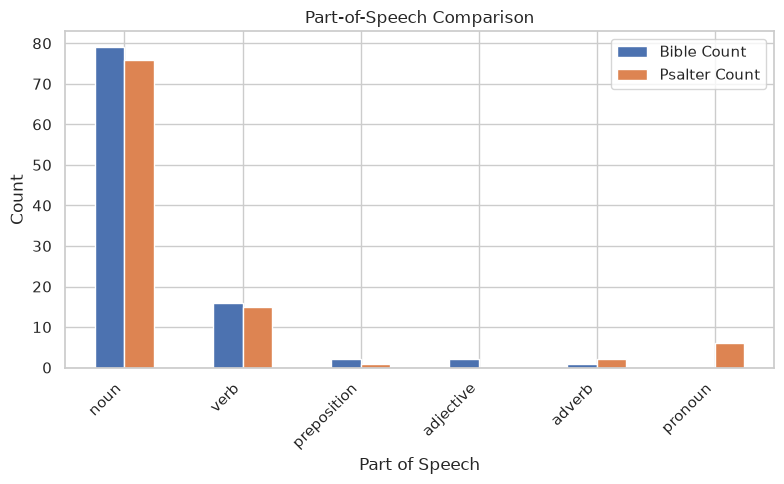

In [124]:
ax = pos_comparison.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Part-of-Speech Comparison")
plt.xlabel("Part of Speech")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

- Nouns dominate both corpora, indicating that topics are primarily defined by key theological concepts and entities.
- Verb frequencies are similar (18 vs. 14), suggesting comparable emphasis on actions and processes.
- The noun counts are nearly identical (76 vs. 75), pointing to strong thematic overlap between the translations.
- Pronouns appear only in the Psalter topics (7 vs. 0), suggesting a more personal or devotional style.
- Propositions and adverbs are rare in both corpora, indicating that function words contribute little to topic formation.
- Overall POS distributions are highly similar, supporting the conclusion that the Bible and Psalter share comparable thematic structures despite minor stylistic differences.

# All Topic words for paper


### 5 Difference Topics

In [126]:
bible5_topic_words

,Topic,Words
0,0,"shall, lord, god, let, like, hand, soul, heart, day, man"
1,1,"god, lord, shall, earth, people, let, psalm, hand, pause, sing"
2,2,"lord, god, shall, end, man, david, heart, may, lawlessness, soul"
3,3,"lord, forever, shall, commandment, praise, mercy, endures, give, ordinance, word"
4,4,"lord, onean, ascent, ode, like, shall, israel, let, soul, house"


In [127]:
psalter5_topics

,Topic,Words
0,0,"lord, thy, thou, god, shall, unto, ever, hath, thee, mercy"
1,1,"me, lord, thou, thy, unto, shall, thee, god, let, hast"
2,2,"shall, god, lord, thy, thou, unto, earth, thee, upon, israel"
3,3,"thy, shall, lord, thou, me, word, heart, commandment, thee, law"
4,4,"lord, praise, ye, earth, shall, glory, unto, god, sing, him"


### 10 Topics

In [128]:
bible10_topic_words

,Topic,Words
0,0,"lord, god, end, shall, david, man, may, heart, psalm, enemy"
1,1,"shall, god, let, lord, like, day, man, hand, poor, earth"
2,2,"god, shall, earth, pause, psalm, end, lord, troubled, people, sing"
3,3,"lord, soul, shall, eye, heart, way, david, sin, god, mercy"
4,4,"lord, shall, david, hand, bless, soul, work, mercy, fear, hope"
5,5,"lord, shall, earth, god, let, glory, people, king, voice, psalm"
6,6,"onean, ascent, lord, ode, israel, like, shall, let, would, house"
7,7,"praise, lord, alleluia, shall, age, name, heaven, people, earth, unto"
8,8,"lord, commandment, forever, endures, mercy, law, ordinance, give, word, testimony"
9,9,"god, shall, inscription, pillar, onefor, end, king, right, hand, people"


In [129]:
psalter10_topic_words

,Topic,Words
0,0,"lord, ever, mercy, endureth, thy, shall, thou, work, hath, hast"
1,1,"lord, shall, unto, zion, god, thee, earth, israel, blessed, house"
2,2,"thy, shall, me, lord, thou, word, commandment, law, way, let"
3,3,"me, thy, thou, thee, unto, god, lord, shall, hast, day"
4,4,"me, lord, shall, thou, let, unto, thee, god, upon, him"
5,5,"thou, me, thee, unto, thy, god, lord, hath, shall, soul"
6,6,"lord, praise, ye, earth, glory, people, sing, unto, shall, king"
7,7,"god, thy, thou, shall, earth, mountain, unto, lord, thee, hast"
8,8,"god, tabernacle, thy, thou, hast, lord, shall, hath, me, mine"
9,9,"god, thou, shall, hast, heart, people, long, lord, iniquity, said"



## Assigned Topic to Each Psalm

In [131]:
bible_model

In [133]:
bibleTopics = bible_model.get_document_info(bible['cleaned_verse'])

In [134]:
bibleTopics = bibleTopics.reset_index()
bibleTopics

index  \
0        0   
1        1   
2        2   
3        3   
4        4   
..     ...   
146    146   
147    147   
148    148   
149    149   
150    150   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            Document  \
0                                                                                                                                                                                                                                                                                                                                blessed man walk counsel ungodly stand way sinner sits seat troublesome law lord law meditates day night shall like tree planted stream water produce fruit season leaf shall wither whatever shall prosper ungodly like dust wind drive face earth therefore ungodly shall rise judgment sinner counsel righteous lord know way righteous way ungodly shall perish   
1                                                                                                              nation rage people meditate vain thing king earth set ruler gather together lord anointed saying let u break band cast away yoke u sits heaven shall laugh lord shall mock shall speak wrath trouble anger established king holy hill zion declaring lord decree lord said son today begotten ask give nation inheritance end earth possession shall shepherd iron staff shall shatter like potter vessel king understand instructed judge earth serve lord fear rejoice trembling lay hold instruction lest lord angry perish righteous way fury shall quickly kindled blessed trust   
2                                                                                                                                                                                                                                                                                                                                                 psalm david fled face son absalom olord afflict multiply many rise many say soul salvation god pause lord protector glory one lift head cried lord voice heard holy hill pause lay slept iawoke lord help afraid ten thousand people set around arise lord save god struck foolishly enmity broke teeth sinner salvation lord blessing upon people   
3                                                                                                                                                                                                                                                    end psalm ode david heard icalled god righteousness strengthened heart distress mercy hear prayer long son men slow heart love vain thing seek lie know lord made holy one wondrous lord hear cry angry sin remorse upon bed say heart pause offer sacrifice righteousness hope lord many say show u good thing lord light face stamped upon u put gladness heart season wheat wine oil multiplied sleep rest peace alone lord cause dwell hope   
4    end concerning inheritance psalm david give ear tomy word lord hear cry give heed voice supplication king god pray lord morning shall hear voice morning stand watch god will lawlessness shall evildoer dwell lawless shall stand eye hate worker lawlessness shall destroy speak falsehood lord abhors man violence deceit fullness mercy come house fear worship toward holy temple lead lord righteousness enemy make straight way truth mo

In [135]:
bibleTopics = bibleTopics.rename(columns={'index': 'Psalm Num'})

bibleTopics['Psalm Num'] = bibleTopics['Psalm Num'] + 1

In [136]:
bibleTopics

Psalm Num  \
0            1   
1            2   
2            3   
3            4   
4            5   
..         ...   
146        147   
147        148   
148        149   
149        150   
150        151   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            Document  \
0                                                                                                                                                                                                                                                                                                                                blessed man walk counsel ungodly stand way sinner sits seat troublesome law lord law meditates day night shall like tree planted stream water produce fruit season leaf shall wither whatever shall prosper ungodly like dust wind drive face earth therefore ungodly shall rise judgment sinner counsel righteous lord know way righteous way ungodly shall perish   
1                                                                                                              nation rage people meditate vain thing king earth set ruler gather together lord anointed saying let u break band cast away yoke u sits heaven shall laugh lord shall mock shall speak wrath trouble anger established king holy hill zion declaring lord decree lord said son today begotten ask give nation inheritance end earth possession shall shepherd iron staff shall shatter like potter vessel king understand instructed judge earth serve lord fear rejoice trembling lay hold instruction lest lord angry perish righteous way fury shall quickly kindled blessed trust   
2                                                                                                                                                                                                                                                                                                                                                 psalm david fled face son absalom olord afflict multiply many rise many say soul salvation god pause lord protector glory one lift head cried lord voice heard holy hill pause lay slept iawoke lord help afraid ten thousand people set around arise lord save god struck foolishly enmity broke teeth sinner salvation lord blessing upon people   
3                                                                                                                                                                                                                                                    end psalm ode david heard icalled god righteousness strengthened heart distress mercy hear prayer long son men slow heart love vain thing seek lie know lord made holy one wondrous lord hear cry angry sin remorse upon bed say heart pause offer sacrifice righteousness hope lord many say show u good thing lord light face stamped upon u put gladness heart season wheat wine oil multiplied sleep rest peace alone lord cause dwell hope   
4    end concerning inheritance psalm david give ear tomy word lord hear cry give heed voice supplication king god pray lord morning shall hear voice morning stand watch god will lawlessness shall evildoer dwell lawless shall stand eye hate worker lawlessness shall destroy speak falsehood lord abhors man violence deceit fullness mercy come house fear worship toward holy temple lead lor

In [137]:
topic_dist_df = (
    bibleTopics['Topic']
    .value_counts(normalize=True)
    .mul(100)
    .reset_index()
)

topic_dist_df.columns = ['Topic', 'Percentage']

topic_dist_df

,Topic,Percentage
0,0,37.748344
1,1,19.867550
2,2,19.205298
3,3,14.569536
4,4,8.609272


In [138]:
psalterTopics = topic_model.get_document_info(psalter['cleaned_verse'])

In [139]:
psalterTopics = psalterTopics.reset_index()

In [140]:
psalterTopics = psalterTopics.rename(columns={'index': 'Psalm Num'})

psalterTopics['Psalm Num'] = psalterTopics['Psalm Num'] + 1

In [141]:
psalterTopics['Topic'].value_counts(normalize=True)

Topic
0    0.140000
1    0.140000
2    0.133333
3    0.126667
4    0.113333
5    0.093333
6    0.093333
7    0.073333
8    0.053333
9    0.033333
Name: proportion, dtype: float64

In [142]:
bible_dist = bibleTopics['Topic'].value_counts(normalize=True)
psalter_dist = psalterTopics['Topic'].value_counts(normalize=True)

comparison = pd.concat(
    [bible_dist, psalter_dist],
    axis=1,
    keys=['Bible', 'Psalter']
).fillna(0)

comparison = comparison.reset_index()
comparison.columns = ['Topic', 'Bible_Proportion', 'Psalter_Proportion']

comparison

,Topic,Bible_Proportion,Psalter_Proportion
0,0,0.377483,0.140000
1,1,0.198675,0.140000
2,2,0.192053,0.133333
3,3,0.145695,0.126667
4,4,0.086093,0.113333
5,5,0.000000,0.093333
6,6,0.000000,0.093333
7,7,0.000000,0.073333
8,8,0.000000,0.053333
9,9,0.000000,0.033333


## Comparing Topic difference between Psalter and Bible

Invesitgating if the topic number is the same for both the Psalter and Bible

In [145]:
differences = 0 

for i in range(150):
        if psalterTopics.iloc[i]["Topic"] != bibleTopics.iloc[i]["Topic"]:
            differences +=1
            
print(differences)

142


In [146]:
from collections import defaultdict
import pandas as pd

topic_diff_counts = defaultdict(int)
differences = 0

for i in range(150):
    psalter_topic = psalterTopics.iloc[i]["Topic"]
    bible_topic = bibleTopics.iloc[i]["Topic"]

    combo = f"{bible_topic} - {psalter_topic}"
    topic_diff_counts[combo] += 1

    if bible_topic != psalter_topic:
        differences += 1

# convert to DataFrame
df = pd.DataFrame(
    topic_diff_counts.items(),
    columns=["Bible - Psalter", "Frequency"]
)

print(differences)
df

142


,Bible - Psalter,Frequency
0,0 - 2,10
1,2 - 7,4
2,0 - 4,12
3,1 - 2,6
4,1 - 3,7
5,1 - 0,2
6,0 - 0,6
7,1 - 4,5
8,1 - 9,2
9,0 - 8,4


In [147]:
df.iloc[df['Frequency'].idxmax()]

Bible - Psalter    0 - 4
Frequency             12
Name: 2, dtype: object

In [148]:
df=df.sort_values(by='Bible - Psalter')

Text(0.5, 1.0, 'Unique Combination of Topics between Psalter and Bible')

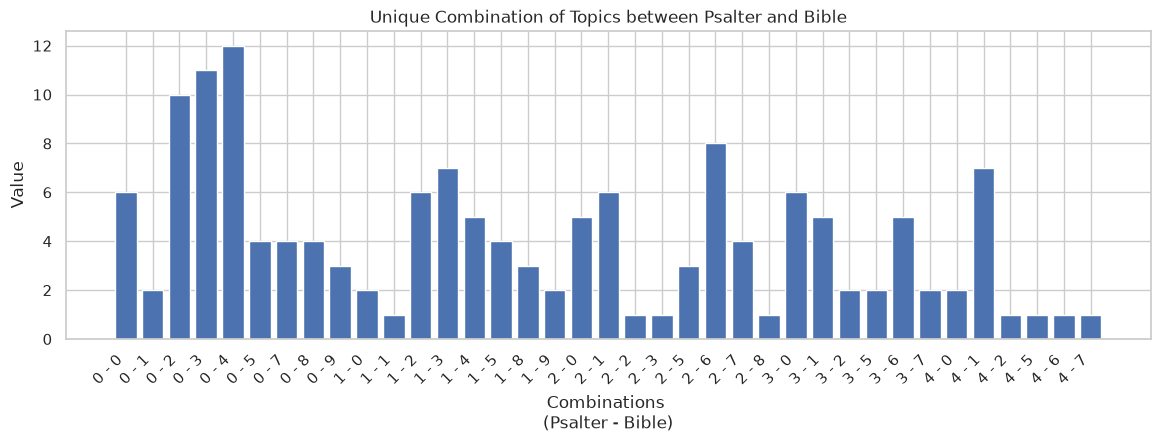

In [149]:

# Create bar chart
plt.figure(figsize=(14,4))
plt.bar(data=df, x="Bible - Psalter", height="Frequency")

# Labels and title
plt.xlabel('Combinations \n(Psalter - Bible)')
plt.xticks(rotation=45, ha='right')

plt.ylabel('Value')
plt.title('Unique Combination of Topics between Psalter and Bible')

# Show plot

# Comparing Topic Embeddings Between Each Source

In [150]:
overall_topics

,topic_id,Bible - word,Weight,Psalter - word,Psalter Weight,Psalter Topic POS,Bible Topic POS
0,0,lord,0.058299,lord,0.060137,noun,noun
1,0,god,0.053114,ever,0.05655,adverb,noun
2,0,end,0.044135,mercy,0.051372,noun,noun
3,0,shall,0.037196,endureth,0.043723,noun,verb
4,0,david,0.036609,thy,0.037553,noun,noun
...,...,...,...,...,...,...,...
95,9,end,0.028459,people,0.041771,noun,noun
96,9,king,0.027372,long,0.039792,adverb,noun
97,9,right,0.026314,lord,0.036662,noun,noun
98,9,hand,0.02612,iniquity,0.034899,noun,noun


In [151]:
bible_weights = (
    overall_topics.groupby("Bible - word")["Weight"]
    .mean()
)

psalter_weights = (
    overall_topics.groupby("Psalter - word")["Psalter Weight"]
    .mean()
)

shared_words = set(bible_weights.index) & set(psalter_weights.index)

comparison = pd.DataFrame({
    "Bible Weight": bible_weights.loc[list(shared_words)],
    "Psalter Weight": psalter_weights.loc[list(shared_words)]
})

comparison["Difference"] = (
    comparison["Bible Weight"] -
    comparison["Psalter Weight"]
)


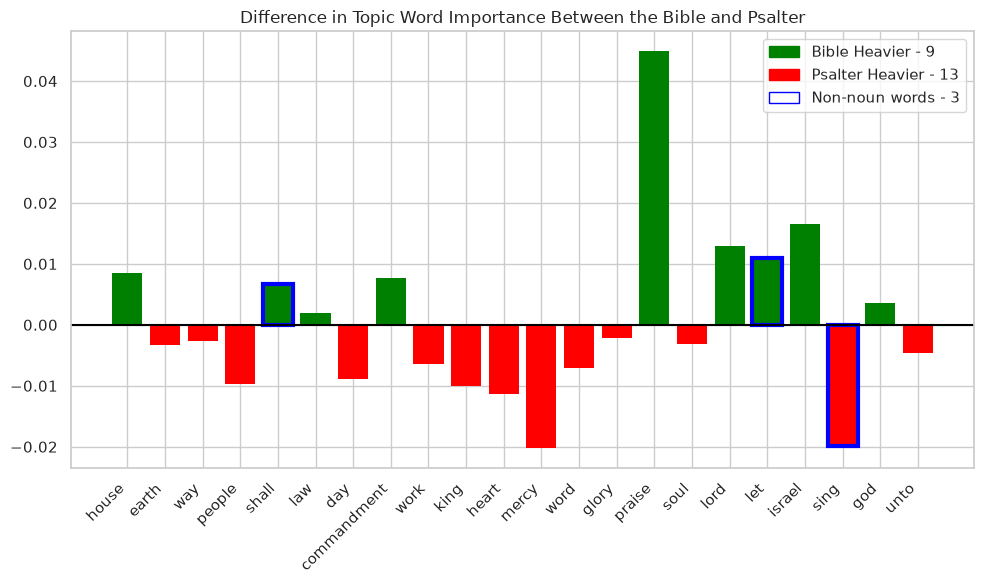

In [152]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

comparison["POS"] = comparison.index.to_series().apply(tag_word)

colors = ["green" if x > 0 else "red"
          for x in comparison["Difference"]]

edges = ["blue" if x != "noun" else (0, 0, 0, 0)
         for x in comparison["POS"]]

plt.figure(figsize=(10, 6))

plt.bar(
    comparison.index,
    comparison["Difference"],
    color=colors,
    edgecolor=edges,
    linewidth=3
)

counts = pd.Series(colors).value_counts().to_dict()
non_nouns = pd.Series(edges).value_counts().to_dict()


plt.axhline(0, color="black")

plt.xticks(rotation=45, ha="right")
plt.title("Difference in Topic Word Importance Between the Bible and Psalter")
green_patch = mpatches.Patch(color='green', label=f'Bible Heavier - {counts["green"]}')
red_patch = mpatches.Patch(color='red', label=f'Psalter Heavier - {counts["red"]}')

edge_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="blue",
    label=f"Non-noun words - {non_nouns['blue']}" 
)

plt.legend(handles=[green_patch, red_patch, edge_patch])

plt.tight_layout()
plt.show()

Normalized word weights to reduce corpus size bias and improve comparability across translations. Replaced manual vocabulary intersection with full alignment using `pd.concat(...).fillna(0)` to preserve translation-specific terms. Used log-ratio instead of raw difference for a more stable and interpretable measure of directional divergence.

In [153]:
bible_weights = (
    overall_topics
    .groupby("Bible - word")["Weight"]
    .mean()
    .pipe(lambda x: x / x.sum())
)

psalter_weights = (
    overall_topics
    .groupby("Psalter - word")["Psalter Weight"]
    .mean()
    .pipe(lambda x: x / x.sum())
)

In [154]:
comparison = pd.concat(
    [bible_weights, psalter_weights],
    axis=1,
    keys=["Bible", "Psalter"]
).fillna(0)


In [155]:
comparison["POS"] = comparison.index.to_series().apply(tag_word)

comparison

,Bible,Psalter,POS
age,0.024096,0,noun
alleluia,0.029672,0,noun
ascent,0.044173,0,noun
bless,0.012768,0,noun
commandment,0.019472,0.02124,noun
...,...,...,...
thou,0,0.027081,noun
thy,0,0.032189,noun
upon,0,0.015112,preposition
ye,0,0.040812,noun


In [156]:
comparison["Difference"] = comparison["Bible"] - comparison["Psalter"]

$$
\text{Log Ratio} = \log\left(\frac{{\text{Bible Weight}}}{{\text{Psalter Weight}}}\right)
$$

In [158]:
import numpy as np

comparison["Bible"] = pd.to_numeric(comparison["Bible"], errors="coerce")
comparison["Psalter"] = pd.to_numeric(comparison["Psalter"], errors="coerce")

comparison["Log_Ratio"] = np.log(
    (comparison["Bible"] + 1e-9) /
    (comparison["Psalter"] + 1e-9)
)

In [159]:
comparison

,Bible,Psalter,POS,Difference,Log_Ratio
age,0.024096,0.000000,noun,0.024096,16.997577
alleluia,0.029672,0.000000,noun,0.029672,17.205721
ascent,0.044173,0.000000,noun,0.044173,17.603631
bless,0.012768,0.000000,noun,0.012768,16.362456
commandment,0.019472,0.021240,noun,-0.001767,-0.086879
...,...,...,...,...,...
thou,0.000000,0.027081,noun,-0.027081,-17.114327
thy,0.000000,0.032189,noun,-0.032189,-17.287151
upon,0.000000,0.015112,preposition,-0.015112,-16.530985
ye,0.000000,0.040812,noun,-0.040812,-17.524496


<Figure size 1200x600 with 0 Axes>

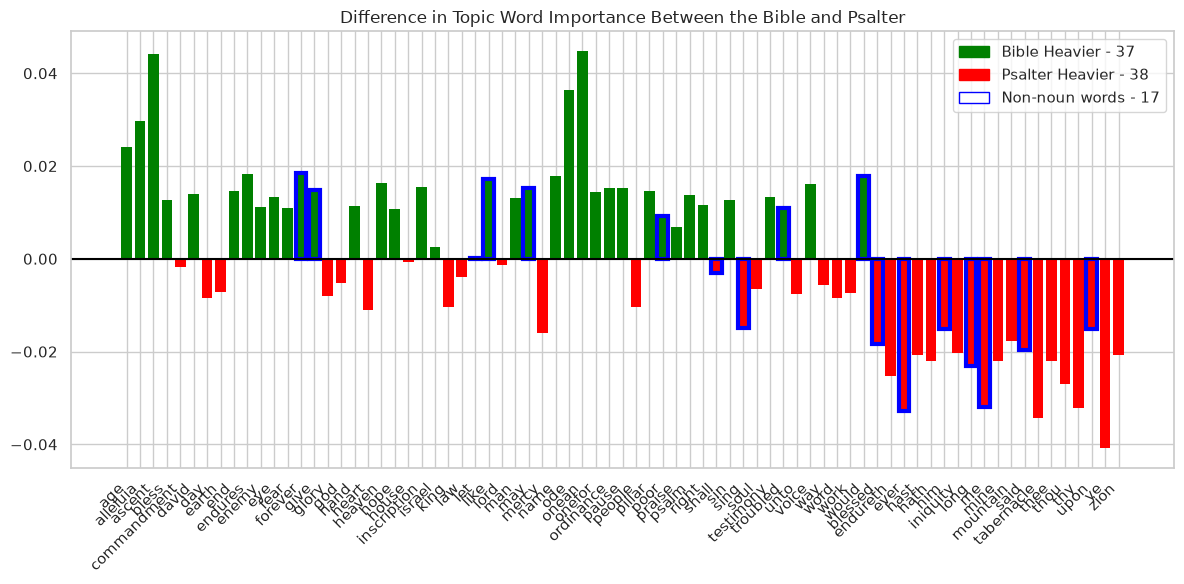

In [160]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.figure(figsize=(12, 6))

comparison["POS"] = comparison.index.to_series().apply(tag_word)

colors = ["green" if x > 0 else "red"
          for x in comparison["Difference"]]

edges = ["blue" if x != "noun" else (0, 0, 0, 0)
         for x in comparison["POS"]]

plt.figure(figsize=(12, 6))

plt.bar(
    comparison.index,
    comparison["Difference"],
    color=colors,
    edgecolor=edges,
    linewidth=3
)

counts = pd.Series(colors).value_counts().to_dict()
non_nouns = pd.Series(edges).value_counts().to_dict()


plt.axhline(0, color="black")

plt.xticks(rotation=45, ha="right")
plt.title("Difference in Topic Word Importance Between the Bible and Psalter")
green_patch = mpatches.Patch(color='green', label=f'Bible Heavier - {counts["green"]}')
red_patch = mpatches.Patch(color='red', label=f'Psalter Heavier - {counts["red"]}')

edge_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="blue",
    label=f"Non-noun words - {non_nouns['blue']}" 
)

plt.legend(handles=[green_patch, red_patch, edge_patch])

plt.tight_layout()
plt.show()

## Topic Differences